# Part 3 of 3: Literature audit, sample-size dependence and field-level impact

**Study:** Data leakage in ICU prediction pipelines built on MIMIC-IV and eICU-CRD

Part 1 built leakage-safe cohorts and features. Part 2 switched on 17 leakage mechanisms one at a time, measured how
much each one inflates performance, and tested whether `icu-leakage-check` detects it. This notebook takes those
measurements to the published literature and to practice:

1. **Literature audit.** It retrieves every MIMIC-IV and eICU-CRD prediction study indexed in Europe PMC, screens titles
   and abstracts with transparent rules, and reads the open-access full texts. Each paper gets 17 leakage indicators,
   one per Part 2 mechanism, plus seven transparency indicators. Every coded value comes with the sentence it was
   based on.
2. **Human validation.** A random sample of papers, plus extra flagged papers for rare indicators, is exported as a
   coding sheet. Once one or two people have coded it, the notebook estimates how accurate the rules are and corrects
   the prevalence estimates for misclassification.
3. **Prevalence and consequences.** How often each mechanism appears, how this changed over time, whether studies at
   risk report higher AUROC, and whether they are cited more.
4. **Sample-size dependence.** Part 2 found that procedural leaks (repeat stays, preprocessing, feature selection,
   resampling, threshold and hyperparameter reuse) hardly matter at 40,000 to 130,000 stays. Here they are repeated
   inside simulated studies of 500 to 10,000 stays, the size of most published subcohort studies.
5. **Do leaks add up?** Several content leaks are switched on together, to test whether their effects can be summed.
6. **Field-level optimism.** Prevalence, validated misclassification rates and measured inflation are combined in a
   Monte Carlo model. The result is the expected optimism in the AUROC values the field reports.
7. **Practice.** Alert burden when a hospital plans around a leaky AUROC, the runtime of an audit, a 17-item reporting
   and procurement checklist ranked by evidence, and an audit card that a model developer can hand to a governance
   committee.

**Data use:** the literature part uses public metadata and open-access texts only. Sections 9 to 13 reuse the local
Part 1 files and write aggregate results only. Per-paper indicator values go to `private_reports/`, so you can decide
whether and how to share them.

**Running order.** First run: the notebook downloads the literature (about 30 to 90 minutes, cached), writes the coding
sheet and runs everything else with unvalidated screening estimates. After the coding sheet is filled in, run it again;
cached downloads and simulations are reused and the validated estimates replace the screening ones.

## 1. Configuration

In [1]:
import os
from pathlib import Path

ROOTS = {
    "mimic-iv": Path(os.environ.get("ILC_MIMIC_ROOT", r"C:\icu_parquet\mimic")),
    "eicu": Path(os.environ.get("ILC_EICU_ROOT", r"C:\icu_parquet\eicu")),
}
WORK_DIR = Path(os.environ.get("ILC_WORK_DIR", r"C:\icu_leakage_work"))

# Literature search
SEARCH_START = "2020-08-01"      # first public release of MIMIC-IV
SEARCH_END = "2026-09-30"        # fixed end date, so the corpus does not change between runs
CONTACT_EMAIL = ""               # optional: sent to Europe PMC in the request header as a courtesy
OFFLINE = os.environ.get("ILC_OFFLINE", "0") == "1"   # True: use only the saved literature snapshot
MAX_RECORDS = int(os.environ["ILC_MAX_RECORDS"]) if os.environ.get("ILC_MAX_RECORDS") else None
REQUEST_PAUSE_S = 0.25           # pause between requests

# Validation sample
N_VALIDATE_RANDOM = 100          # random papers to code by hand
N_ENRICH_PER_INDICATOR = 5       # extra papers per indicator among those flagged as at risk
MIN_CODED = 20                   # coded papers needed before validated estimates replace screening estimates

# Local experiments (Part 1 files)
MAX_STAYS = int(os.environ["ILC_MAX_STAYS"]) if os.environ.get("ILC_MAX_STAYS") else None
SIZES = [500, 1000, 2000, 5000, 10000]   # simulated study sizes (ICU stays)
SIZE_REPEATS = int(os.environ.get("ILC_SIZE_REPEATS", "20"))
MODELS = ["logistic", "hgb"]
N_BOOT = int(os.environ.get("ILC_N_BOOT", "200"))
N_MC = int(os.environ.get("ILC_N_MC", "2000"))
TOP_K_FEATURES = 30
SMOTE_K = 5
AUDIT_SIZES = [1000, 5000, 20000]
RESUME = True
SEED = 20261015

INDEX_MIN = 24 * 60

In [2]:
import gzip
import hashlib
import json
import platform
import re
import sys
import time
import unicodedata
import urllib.error
import urllib.parse
import urllib.request
import warnings
import xml.etree.ElementTree as ET
import zlib
from datetime import datetime, timezone

import matplotlib
import matplotlib.patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import stats
from scipy.optimize import brentq
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import icu_leakage_check as ilc

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)

RUN_START = time.time()
P1 = WORK_DIR / "part1"
P1_DATA = P1 / "data"
P2 = WORK_DIR / "part2"
PART_DIR = WORK_DIR / "part3"
RESULTS_DIR = PART_DIR / "results"
TABLES_DIR = RESULTS_DIR / "tables"
FIG_DIR = RESULTS_DIR / "figures"
RAW_DIR = RESULTS_DIR / "raw"
PACK_DIR = RESULTS_DIR / "evidence_pack"
PRIVATE_DIR = PART_DIR / "private_reports"
CODING_DIR = PART_DIR / "coding"
SNAP = PART_DIR / "literature_snapshot"
for d in (TABLES_DIR, FIG_DIR, RAW_DIR, PACK_DIR, PRIVATE_DIR, CODING_DIR, SNAP / "search", SNAP / "fulltext"):
    d.mkdir(parents=True, exist_ok=True)

part1_manifest = json.loads((P1 / "manifest_part1.json").read_text())
part2_manifest = json.loads((P2 / "manifest_part2.json").read_text())
ENV = {
    "run_started_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "python": sys.version.split()[0], "platform": platform.platform(), "icu_leakage_check": ilc.__version__,
    "pandas": pd.__version__, "numpy": np.__version__, "scikit_learn": sklearn.__version__, "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
}
CONFIG = {k: v for k, v in dict(SEARCH_START=SEARCH_START, SEARCH_END=SEARCH_END, MAX_RECORDS=MAX_RECORDS,
                                N_VALIDATE_RANDOM=N_VALIDATE_RANDOM, N_ENRICH_PER_INDICATOR=N_ENRICH_PER_INDICATOR,
                                MIN_CODED=MIN_CODED, MAX_STAYS=MAX_STAYS, SIZES=SIZES, SIZE_REPEATS=SIZE_REPEATS,
                                MODELS=MODELS, N_BOOT=N_BOOT, N_MC=N_MC, TOP_K_FEATURES=TOP_K_FEATURES,
                                SMOTE_K=SMOTE_K, AUDIT_SIZES=AUDIT_SIZES, SEED=SEED).items()}
CONFIG["part2_chain_sha256"] = part2_manifest["chain_sha256"]
print(json.dumps(ENV, indent=2))
print("Part 1 chain digest:", part1_manifest["chain_sha256"])
print("Part 2 chain digest:", part2_manifest["chain_sha256"])

LABEL = {"mimic-iv": "MIMIC-IV", "eicu": "eICU-CRD"}
OKABE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]
MECH = {
    "E01": ("Repeat stays of test patients in training", "Split integrity"),
    "E01b": ("Row-level random split (as reported)", "Split integrity"),
    "E02": ("Look-ahead: features beyond the prediction time", "Timing"),
    "E03": ("Clinical-time filter ignoring result availability", "Timing"),
    "E04": ("Full totals of running infusions and ventilation", "Timing"),
    "E05": ("Discharge fields and length of stay", "Hindsight"),
    "E06": ("Outcome column next to predictors", "Outcome encoding"),
    "E07": ("Same-admission billing codes and diagnoses", "Undated or late source"),
    "E08": ("Care limitation and code status, any time", "Outcome proxy"),
    "E09": ("First-day severity summaries in an earlier model", "First-day summary"),
    "E10": ("Patients already in the outcome kept in the cohort", "Post-outcome instances"),
    "E10b": ("Patients already in the outcome kept (as reported)", "Post-outcome instances"),
    "E11": ("Preprocessing fitted on all rows", "Preprocessing"),
    "E12": ("Feature selection on all rows", "Preprocessing"),
    "E13": ("Resampling before the split", "Resampling"),
    "E13b": ("Resampling before the split (as reported)", "Resampling"),
    "E14": ("Threshold chosen on the test set", "Evaluation reuse"),
    "E15": ("Hyperparameters or final model chosen on the test set", "Evaluation reuse"),
    "E16": ("Temporal validation on shifted dates", "Split order"),
    "E17": ("Overlapping data presented as external", "Site overlap"),
}


def stable_seed(*parts):
    return (zlib.crc32("|".join(map(str, parts)).encode()) + SEED) % (2 ** 31)


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight", metadata={"Software": None})
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight", metadata={"CreationDate": None, "Producer": None, "Creator": None})
    plt.show()


def save_table(df, name, index=False):
    df.to_csv(TABLES_DIR / f"{name}.csv", index=index, float_format="%.6g")

{
  "run_started_utc": "2026-10-22T03:05:57Z",
  "python": "3.11.5",
  "platform": "Windows-10-10.0.26200-SP0",
  "icu_leakage_check": "0.1.0",
  "pandas": "3.0.6",
  "numpy": "2.4.6",
  "scikit_learn": "1.9.1",
  "scipy": "1.17.1",
  "matplotlib": "3.11.2"
}
Part 1 chain digest: a84f339e2d0379e400b33d1c27efee99ba73e26c243596bd2052467c88d11eeb
Part 2 chain digest: 36cffffe5a1ec6d4cb8e81e8858a1795b5a7a94db7295db937fb50051937667f


## 2. Literature retrieval

**Source:** the Europe PMC REST API (free, no key). It indexes PubMed, PubMed Central and preprint servers, and it
returns open-access full texts as JATS XML.

**Query:** MIMIC-IV or eICU-CRD in the title or abstract, AND a prediction term, AND a first publication date between
`SEARCH_START` and `SEARCH_END`.

Every response is saved under `literature_snapshot/`. A rerun replays the snapshot, so the corpus is frozen and
reproducible. If you set `OFFLINE = True`, nothing is downloaded.

In [3]:
EPMC = "https://www.ebi.ac.uk/europepmc/webservices/rest/"
HEADERS = {"User-Agent": f"icu-leakage-check literature audit ({CONTACT_EMAIL or 'no contact given'})",
           "Accept": "application/json, application/xml;q=0.9, */*;q=0.8"}
DB_TERMS = ['"MIMIC-IV"', '"MIMIC IV"', '"MIMIC-4"', '"eICU"', '"eICU-CRD"', '"eICU Collaborative Research Database"']
PRED_TERMS = ["predict*", "prognos*", "nomogram*", '"machine learning"', '"deep learning"', '"risk score"',
              '"early warning"', '"risk model"']


def field_or(terms):
    return "(" + " OR ".join(f"TITLE:{t} OR ABSTRACT:{t}" for t in terms) + ")"


QUERY = (f"{field_or(DB_TERMS)} AND {field_or(PRED_TERMS)} AND FIRST_PDATE:[{SEARCH_START} TO {SEARCH_END}] "
         f"AND (SRC:MED OR SRC:PMC OR SRC:PPR)")


def fetch(url, timeout=90):
    # Returns (bytes or None, status); retries with back-off on rate limits and transient errors
    if OFFLINE:
        return None, "offline"
    wait = 2.0
    for attempt in range(7):
        try:
            req = urllib.request.Request(url, headers=HEADERS)
            with urllib.request.urlopen(req, timeout=timeout) as r:
                data = r.read()
            time.sleep(REQUEST_PAUSE_S)
            return data, "ok"
        except urllib.error.HTTPError as e:
            if e.code in (400, 404, 410):
                return None, f"http {e.code}"
        except (urllib.error.URLError, TimeoutError, ConnectionError, OSError):
            pass
        time.sleep(wait)
        wait = min(wait * 2, 90)
    return None, "failed after retries"


def run_search(query, page_size=1000):
    sdir = SNAP / "search"
    meta_p = sdir / "query.json"
    if meta_p.exists():
        meta = json.loads(meta_p.read_text())
        same = meta.get("query") == query and meta.get("max_records") == MAX_RECORDS
        if same and meta.get("complete"):
            pages = [json.loads(gzip.decompress(p.read_bytes())) for p in sorted(sdir.glob("page_*.json.gz"))]
            print(f"Replaying saved search from {meta['retrieved_utc']}: {meta['pages']} pages")
            return meta, pages
    if OFFLINE:
        raise RuntimeError("OFFLINE is set but no complete literature snapshot exists in " + str(sdir))
    for p in sdir.glob("page_*.json.gz"):
        p.unlink()
    pages, cursor, n_have = [], "*", 0
    while True:
        params = {"query": query, "format": "json", "resultType": "core", "pageSize": page_size,
                  "cursorMark": cursor, "synonym": "false"}
        data, status = fetch(EPMC + "search?" + urllib.parse.urlencode(params))
        if data is None and not pages and page_size > 100:
            page_size = 100
            continue
        if data is None:
            raise RuntimeError(f"Europe PMC search failed ({status}); rerun later, finished pages are not kept")
        js = json.loads(data)
        (sdir / f"page_{len(pages):04d}.json.gz").write_bytes(gzip.compress(data))
        pages.append(js)
        res = js.get("resultList", {}).get("result", [])
        n_have += len(res)
        if len(pages) == 1:
            print(f"Europe PMC reports {js.get('hitCount', 0):,} matching records")
        if len(pages) % 5 == 0:
            print(f"  {n_have:,} records retrieved")
        nxt = js.get("nextCursorMark")
        if not res or not nxt or nxt == cursor or (MAX_RECORDS and n_have >= MAX_RECORDS):
            break
        cursor = nxt
    meta = {"query": query, "retrieved_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
            "hit_count": pages[0].get("hitCount"), "pages": len(pages), "max_records": MAX_RECORDS, "complete": True}
    meta_p.write_text(json.dumps(meta, indent=2))
    return meta, pages


search_meta, pages = run_search(QUERY)
print("Query:", QUERY)

Replaying saved search from 2026-10-16T04:52:35Z: 5 pages
Query: (TITLE:"MIMIC-IV" OR ABSTRACT:"MIMIC-IV" OR TITLE:"MIMIC IV" OR ABSTRACT:"MIMIC IV" OR TITLE:"MIMIC-4" OR ABSTRACT:"MIMIC-4" OR TITLE:"eICU" OR ABSTRACT:"eICU" OR TITLE:"eICU-CRD" OR ABSTRACT:"eICU-CRD" OR TITLE:"eICU Collaborative Research Database" OR ABSTRACT:"eICU Collaborative Research Database") AND (TITLE:predict* OR ABSTRACT:predict* OR TITLE:prognos* OR ABSTRACT:prognos* OR TITLE:nomogram* OR ABSTRACT:nomogram* OR TITLE:"machine learning" OR ABSTRACT:"machine learning" OR TITLE:"deep learning" OR ABSTRACT:"deep learning" OR TITLE:"risk score" OR ABSTRACT:"risk score" OR TITLE:"early warning" OR ABSTRACT:"early warning" OR TITLE:"risk model" OR ABSTRACT:"risk model") AND FIRST_PDATE:[2020-08-01 TO 2026-09-30] AND (SRC:MED OR SRC:PMC OR SRC:PPR)


In [4]:
def strip_tags(s):
    return " ".join(re.sub(r"<[^>]+>", " ", s or "").split())


def norm_title(t):
    return re.sub(r"[^a-z0-9]+", " ", (t or "").lower()).strip()


rows = []
for js in pages:
    for r in js.get("resultList", {}).get("result", []):
        ji = r.get("journalInfo") or {}
        journal = (ji.get("journal") or {}).get("title") or (r.get("bookOrReportDetails") or {}).get("publisher") or ""
        pts = (r.get("pubTypeList") or {}).get("pubType") or []
        pts = [pts] if isinstance(pts, str) else list(pts)
        first = r.get("firstPublicationDate") or ""
        year = pd.to_numeric(r.get("pubYear"), errors="coerce")
        if not (isinstance(year, (int, float)) and year >= 2000) and first[:4].isdigit():
            year = int(first[:4])
        rows.append({
            "epmc_id": r.get("id"), "source": r.get("source"), "pmid": r.get("pmid"), "pmcid": r.get("pmcid"),
            "doi": (r.get("doi") or "").lower() or None, "title": strip_tags(r.get("title")),
            "abstract": strip_tags(r.get("abstractText")), "journal": journal, "pub_year": year, "first_date": first,
            "is_open_access": r.get("isOpenAccess") == "Y", "in_epmc": r.get("inEPMC") == "Y",
            "cited_by": int(r.get("citedByCount") or 0), "pub_types": "; ".join(pts),
            "is_preprint": r.get("source") == "PPR" or any("preprint" in p.lower() for p in pts),
        })
records = pd.DataFrame(rows)
records["norm_title"] = records["title"].map(norm_title)
records["_prio"] = (records["is_preprint"].astype(int) * 4 + records["pmcid"].isna().astype(int) * 2
                    + (records["source"] != "MED").astype(int))
records = records.sort_values(["_prio", "epmc_id"]).reset_index(drop=True)
flow = [("Records retrieved from Europe PMC", len(records))]
for key in ("doi", "pmid", "pmcid", "norm_title"):
    dup = records[key].notna() & (records[key] != "") & records.duplicated(key)
    records = records[~dup]
    flow.append((f"Duplicates removed by {dict(doi='DOI', pmid='PMID', pmcid='PMCID', norm_title='title')[key]}", int(dup.sum())))
records = records.drop(columns="_prio").reset_index(drop=True)
records["paper_key"] = np.where(records["pmcid"].notna(), records["pmcid"],
                                np.where(records["pmid"].notna(), "PMID" + records["pmid"].astype(str), records["epmc_id"]))
flow.append(("Unique records", len(records)))
print(pd.DataFrame(flow, columns=["step", "n"]).to_string(index=False))

                             step    n
Records retrieved from Europe PMC 3957
        Duplicates removed by DOI    1
       Duplicates removed by PMID    0
      Duplicates removed by PMCID    0
      Duplicates removed by title   97
                   Unique records 3859


## 3. Title and abstract screening

The rules below run in order, and the first one that applies gives the exclusion reason. They aim at the population
Part 2 measured: patient-level clinical prediction from tabular MIMIC-IV or eICU-CRD data, with a discrimination
metric. Some studies describe no multivariable model in the title or abstract, typically one biomarker's
association with an outcome reported with an AUROC. They are kept but labelled `single marker`, and the main analyses
use multivariable models only.

In [5]:
def RX(p):
    return re.compile(p, re.I)


DB_RX = {"mimic-iv": RX(r"\bmimic[- ]?(iv|4)\b"), "eicu": RX(r"\be-?icu\b|\beicu-crd\b"),
         "mimic-iii": RX(r"\bmimic[- ]?(iii|3)\b")}
NONRESEARCH_RX = RX(r"\b(review|meta-analys|editorial|comment|letter|erratum|correction|retracted|protocol|case report|news)\b")
NONRESEARCH_TITLE_RX = RX(r"\b(systematic review|scoping review|narrative review|meta-analysis|a review|study protocol)\b")
PRED_RX = RX(r"\bpredict|\bprognos|nomogram|machine learning|deep learning|risk (score|model|stratification)|early warning|classif")
PERF_RX = RX(r"\b(auc|auroc|au-?roc|c-?index|c[- ]statistic|concordance|area under|roc curve)\b")
MODALITY_RX = RX(r"x-?ray|radiograph|\bcxr\b|\bct scan|\becg\b|electrocardiogra|waveform|photoplethysm|\bppg\b|clinical notes?|"
                 r"discharge summar|natural language|large language model|\bllms?\b|chatgpt|\bgpt-?\d|\bimag(e|es|ing)\b")
SINGLE_RX = RX(r"\b(associat|relationship|correlat|link between)")
MULTI_TITLE_RX = RX(r"\b(model|nomogram|machine learning|deep learning|algorithm|score|classifier|network|tool)s?\b")
MULTI_ABS_RX = RX(r"machine learning|deep learning|nomogram|predict\w* models?|prognostic models?|risk (prediction )?models?|xgboost|"
                  r"random forest|lightgbm|neural network|models? (was|were) (developed|constructed|built|established)|"
                  r"develop\w* (a|an) (\w+ )?(model|score|nomogram)")


def screen(r):
    ta = f"{r['title']} {r['abstract']}"
    if NONRESEARCH_RX.search(r["pub_types"] or "") and not re.search(r"research-article|journal article", r["pub_types"] or "", re.I):
        return "Review or non-research article"
    if NONRESEARCH_TITLE_RX.search(r["title"]):
        return "Review or non-research article"
    if not (DB_RX["mimic-iv"].search(ta) or DB_RX["eicu"].search(ta)):
        return "MIMIC-IV or eICU-CRD not named in title or abstract"
    if not PRED_RX.search(ta):
        return "Not a prediction study"
    if not PERF_RX.search(r["abstract"] or ""):
        return "No discrimination metric in the abstract"
    if MODALITY_RX.search(r["title"]):
        return "Imaging, waveform or text modality"
    return None


records["exclusion"] = records.apply(screen, axis=1)
records["included"] = records["exclusion"].isna()
records["study_type"] = np.where([not MULTI_TITLE_RX.search(t) and not MULTI_ABS_RX.search(a) for t, a in zip(records["title"], records["abstract"])],
                                 "single marker", "multivariable model")
excl = records["exclusion"].value_counts()
for reason, n in excl.items():
    flow.append((f"Excluded: {reason}", int(n)))
flow.append(("Included after screening", int(records["included"].sum())))
flow.append(("  of which multivariable model studies", int((records["included"] & (records["study_type"] == "multivariable model")).sum())))
flow.append(("  of which preprints", int((records["included"] & records["is_preprint"]).sum())))
print(pd.DataFrame(flow, columns=["step", "n"]).to_string(index=False))

                                                         step    n
                            Records retrieved from Europe PMC 3957
                                    Duplicates removed by DOI    1
                                   Duplicates removed by PMID    0
                                  Duplicates removed by PMCID    0
                                  Duplicates removed by title   97
                                               Unique records 3859
           Excluded: No discrimination metric in the abstract 2006
Excluded: MIMIC-IV or eICU-CRD not named in title or abstract  136
                 Excluded: Imaging, waveform or text modality   49
                             Excluded: Not a prediction study   35
                     Excluded: Review or non-research article   18
                                     Included after screening 1615
                         of which multivariable model studies 1305
                                           of which preprints 

## 4. Full texts

Full texts come from the Europe PMC `fullTextXML` endpoint for included records that have a PubMed Central
identifier. The JATS sections are sorted into abstract, methods, results, discussion, introduction, availability
statements and tables. Introductions and discussions are not used for coding, because they mostly describe other
studies. Records without a full text are coded from the abstract only, and they are compared with the full-text set in
Section 7.

In [6]:
def get_fulltext(pmcid):
    p, miss = SNAP / "fulltext" / f"{pmcid}.xml.gz", SNAP / "fulltext" / f"{pmcid}.missing"
    if p.exists():
        return gzip.decompress(p.read_bytes()).decode("utf-8", "replace")
    if miss.exists() or OFFLINE:
        return None
    data, status = fetch(f"{EPMC}{pmcid}/fullTextXML")
    if data is None:
        miss.write_text(status)
        return None
    p.write_bytes(gzip.compress(data))
    return data.decode("utf-8", "replace")


def local(tag):
    return tag.rsplit("}", 1)[-1] if isinstance(tag, str) else ""


def node_text(el):
    return " ".join(" ".join(el.itertext()).split())


SEC_RULES = [
    ("availability", RX(r"availab|data sharing|code and data|software and data")),
    ("methods", RX(r"method|material|patients|participants|study (design|population|cohort)|data (source|collection|extraction|"
                   r"pre-?processing|processing)|statistic|model (development|construction|building|training)|experiment|"
                   r"feature|variable|cohort|outcome|predictor|setting|algorithm|machine learning|analysis")),
    ("results", RX(r"result|performance|evaluation|validation")),
    ("discussion", RX(r"discussion|conclusion|limitation|strength")),
    ("introduction", RX(r"introduction|background|related work")),
]


def classify_section(title, sec_type):
    s = f"{sec_type} {title}"
    for name, rx in SEC_RULES:
        if rx.search(s):
            return name
    return "other"


def parse_jats(xml):
    xml = re.sub(r"<!DOCTYPE[^>\[]*(\[[^\]]*\])?>", "", xml, count=1)
    try:
        root = ET.fromstring(xml.encode("utf-8"))
    except ET.ParseError:
        return None
    parts = {k: [] for k in ("abstract", "methods", "results", "discussion", "introduction", "other", "availability", "tables")}
    for el in root.iter():
        t = local(el.tag)
        if t == "abstract":
            parts["abstract"].append(node_text(el))
        elif t == "table-wrap":
            cap = " ".join(node_text(c) for c in el if local(c.tag) in ("label", "caption"))
            rows_ = [node_text(tr_) for tr_ in el.iter() if local(tr_.tag) == "tr"]
            parts["tables"].append(" ||| ".join([cap] + rows_))
        elif t in ("sec", "notes", "fn"):
            kind = f"{el.get('sec-type', '')} {el.get('notes-type', '')} {el.get('fn-type', '')}"
            title = next((node_text(c) for c in el if local(c.tag) == "title"), "")
            if re.search(r"availab", kind, re.I) or re.search(r"(data|code|software|material)s?.{0,25}availab|availability of", title, re.I):
                parts["availability"].append(node_text(el))
    body = next((el for el in root.iter() if local(el.tag) == "body"), None)
    if body is not None:
        for child in body:
            t = local(child.tag)
            if t == "sec":
                title = next((node_text(c) for c in child if local(c.tag) == "title"), "")
                parts[classify_section(title, child.get("sec-type", ""))].append(node_text(child))
            elif t == "p":
                parts["other"].append(node_text(child))
    links = [v for el in root.iter() for k, v in el.attrib.items() if k.endswith("href")]
    out = {k: (" ||| " if k == "tables" else " ").join(v) for k, v in parts.items()}
    out["links"] = " ".join(links)
    out["n_chars_body"] = sum(len(out[k]) for k in ("methods", "results", "discussion", "introduction", "other"))
    return out


inc = records[records["included"]].copy()
texts, status = {}, {}
t0 = time.time()
cand = inc[inc["pmcid"].notna()]
for i, (key, pmcid) in enumerate(zip(cand["paper_key"], cand["pmcid"])):
    xml = get_fulltext(pmcid)
    parsed = parse_jats(xml) if xml else None
    if parsed and parsed["n_chars_body"] > 2000:
        texts[key] = parsed
        status[key] = "full text"
    else:
        status[key] = "full text not available" if xml is None else "full text not parseable or too short"
    if (i + 1) % 250 == 0:
        print(f"  {i + 1:,} of {len(cand):,} full texts processed ({(time.time() - t0) / 60:.1f} min)")
inc["text_source"] = inc["paper_key"].map(lambda k: "full text" if k in texts else "abstract only")
inc["fulltext_status"] = inc["paper_key"].map(status).fillna("no PubMed Central identifier")
flow.append(("Included with full text", int((inc["text_source"] == "full text").sum())))
flow.append(("Included with abstract only", int((inc["text_source"] == "abstract only").sum())))
print(inc["fulltext_status"].value_counts().to_string())

  250 of 1,021 full texts processed (0.0 min)
  500 of 1,021 full texts processed (0.1 min)
  750 of 1,021 full texts processed (0.1 min)
  1,000 of 1,021 full texts processed (0.2 min)
fulltext_status
full text                       996
no PubMed Central identifier    594
full text not available          25


## 5. Automated coding: study characteristics and 17 leakage indicators

Each indicator corresponds to one Part 2 mechanism and is coded from sentences in the methods, results and tables (or
the abstract when there is no full text). Values:

* `risk`: the risky practice is described, or a required safeguard is missing (for the three safeguard indicators);
* `safe`: the safeguard is described;
* `unclear`: the practice is described without enough detail to tell which applies;
* `not_mentioned`: the practice is not described;
* `na`: the indicator does not apply to this study.

Every coded value keeps the sentence it was based on. The rules are deliberately simple and transparent; Section 6
measures their accuracy against human coding, and every estimate that matters is corrected for it.

In [7]:
DASHES = dict.fromkeys(map(ord, "\u2010\u2011\u2012\u2013\u2014\u2015\u2212"), "-")
SENT_SPLIT = re.compile(r"(?<=[.!?;])\s+(?=[A-Z0-9(\[])")


def normalise(t):
    t = unicodedata.normalize("NFKC", t or "").translate(DASHES)
    return " ".join(t.replace("\u2265", ">=").replace("\u2264", "<=").split())


def sentences(t):
    return [s for s in SENT_SPLIT.split(normalise(t)) if len(s) > 15]


def P(*rx, none=()):
    return {"all": [RX(r) for r in rx], "none": [RX(r) for r in none]}


ALLDATA = (r"\b(entire|whole|full|complete|overall|all)\b.{0,25}\b(data ?sets?|cohorts?|data|samples?|patients|population|records|observations)\b"
           r"|\b(before|prior to)\b.{0,25}\b(split|splitting|division|dividing|partition\w*|randomi[sz]\w*|separat\w*)\b")
TRAINONLY = (r"\btrain(ing)?\b.{0,30}\b(set|sets|cohort|data|fold|folds|subset|group|sample)\b|\bwithin (each|the) (training )?folds?\b"
             r"|\binner (loop|fold)|\bnested cross")
FEATURE_CTX = (r"\b(variables?|features?|predictors?|covariates?|inputs?|included in the (model|analysis)|candidate|selected|"
               r"importance|important|shap|contribut\w*|model(s|ling|ing)? (with|using|includ))")
TESTSET = r"\b(test(ing)?|validation|hold-?out|internal validation) (sets?|cohorts?|data ?sets?|data|groups?|samples?)\b"
RANDOMSPLIT = (r"\brandom(ly|i[sz]ed)?\b.{0,80}\b(split|divided|divide|assigned|allocated|partitioned|separated|sampled)\b"
               r"|\b(split|divided|assigned|allocated|partitioned)\b.{0,80}\brandom(ly)?\b|\b[78]0 ?%.{0,40}\b[23]0 ?%|\b[78] ?: ?[23]\b")
FIRSTSTAY = (r"\bfirst (icu |intensive care unit |hospital )?(admission|stay|icu stay|visit|record)|\bonly the first\b|"
             r"\b(multiple|repeated?|subsequent) (icu |hospital )?(admissions|stays|visits)\b.{0,80}\b(only|first|excluded|removed)\b|"
             r"\breadmissions? (were|was) excluded|\bone (icu )?(stay|admission) per patient")
PATIENTLEVEL = (r"\bpatient[- ]level (split|partition|division)|\bsplit\w* (by|at the level of|on) (the )?(patient|subject)|"
                r"\bgroup(ed)? (k-?fold|by (patient|subject))|\bsubject_id\b.{0,60}\b(split|group)|\bno patient (appeared|overlap)")
WINDOW = (r"\b(first|initial|within( the first)?)\b.{0,6}\b(1|2|3|4|6|8|12|24|48|72|six|twelve|twenty-four)\s?-?(h|hr|hrs|hours?)\b"
          r"|\b(first|initial) (icu |hospital )?day\b|\bday 1\b|\bon (icu )?admission\b|\bat (the time of )?(icu )?admission\b"
          r"|\b(before|prior to) (the )?(prediction|index) (time|point)\b|\bobservation window\b|\bprediction (window|time|point)\b")
EARLY = (r"\b(within|first|initial|at)\b.{0,10}\b(1|2|3|4|6|8|12|one|two|three|four|six|twelve)\s?-?(h|hr|hrs|hours?)\b"
         r"|\bon admission\b|\bat (icu )?admission\b|\bearly (prediction|warning|identification)\b|\bhourly\b|\breal[- ]time\b|\bdynamic\b")
SCORES = r"\b(apache|saps|sofa|oasis|lods|sapsii|saps[- ]ii|apsiii|aps[- ]iii|sirs)\b"
CARE_LIMIT = (r"\b(do[- ]not[- ]resuscitate|dnr|dni|do[- ]not[- ]intubate|code status|full code|comfort (care|measures)|palliative|"
              r"hospice|withdrawal of (life[- ]sustaining|care|treatment)|limitation of (life[- ]sustaining |care|treatment)|"
              r"end[- ]of[- ]life|goals of care)\b")
PREP = r"\b(imput\w*|normali[sz]\w*|standardi[sz]\w*|z-?score|min-?max|rescal\w*|scal(ed|ing)|winsori[sz]\w*)\b"
SEL = (r"\b(lasso|least absolute shrinkage|boruta|recursive feature elimination|rfe|feature selection|variable selection|"
       r"select\w* (the )?(variables|features|predictors)|univariate (and multivariate |and multivariable )?(logistic|cox|analys\w*)|"
       r"stepwise|mutual information)\b")
RESAMP = (r"\b(smote|adasyn|borderline-?smote|over-?sampl\w*|under-?sampl\w*|random (over|under)\w*|class (imbalance correction|balanc\w*)|"
          r"balanced (the )?data ?set|(re)?sampl\w* (to|for) (address|handle|correct|balance) (the )?(class )?imbalance)\b")
NOT_SPLIT = r"random (forest|search|effects?|seed|state|survival forest)|randomi[sz]ed (controlled|clinical) trial"
ELIGIBILITY = r"\bexclu|\binclusion|\beligib|\b(less|more|longer|shorter) than\b|[<>]=?\s?\d|\bat least\b"
NO_IMPUTE = r"\bnot (performed|used|imputed)|\bwithout imputation|\bno imputation|\bcomplete[- ]case"
THR = (r"\b(youden|optimal (cut-?off|threshold|cut ?point)|cut-?off (value|point)s?|thresholds? (was|were) (selected|chosen|"
       r"determined|set|defined))\b")
TUNE = r"\b(hyper-?parameters?|tun(ed|ing)|grid search|random(ized)? search|bayesian optimi[sz]ation|optuna|hyperopt)\b"
TEMPORAL = (r"\btemporal(ly)? (validat\w*|split\w*|hold-?out|test\w*)|\bchronolog\w*|\bsplit\w* by (admission |calendar )?(year|date|time)"
            r"|\b(earlier|later) (years?|period|admissions)\b.{0,40}\b(train|test|valid)")
TRUE_YEAR = r"anchor_year|anchor year|year group|20(08|11|14|17)\s?(-|to)\s?20(10|13|16|19)"
EXTERNAL = r"\bexternal(ly)?\b.{0,25}\b(validat\w*|test\w*|cohorts?|data ?sets?)"
OTHER_SOURCE = (r"amsterdamumc|hirid|sicdb|zigong|salzburg|\b(our|local|affiliated|university|tertiary|teaching|people'?s|first|second|"
                r"general|regional) (hospital|centre|center|institution|icu)s?\b|\bprospective(ly)?\b|\bmulti-?cent(er|re)\b|\bindependent hospital")
SITE_HOLDOUT = r"\bhospitals?\b.{0,60}\b(held[- ]out|not (included|used)|separate|different|unseen|excluded from training)"
EVENT_TASKS = {"aki", "sepsis", "delirium", "respiratory", "circulatory", "bleeding or thrombosis"}


def applies_all(s):
    return True


INDICATORS = [
    dict(id="I01", mechanism="E01b", leakage_type="ENTITY_OVERLAP", kind="practice", scope="methods", conflict="safe",
         name="Split allows the same patient in training and test",
         rule="Random row-level split or cross-validation without a first-stay rule or a patient-level split.",
         risk=[P(RANDOMSPLIT, none=[NOT_SPLIT])], safe=[P(FIRSTSTAY), P(PATIENTLEVEL)],
         unclear=[P(r"\b(\d+|ten|five)[- ]fold cross[- ]validation\b")],
         applies=applies_all),
    dict(id="I02", mechanism="E02", leakage_type="FUTURE_EVENT", kind="practice", scope="methods", conflict="unclear",
         name="Features summarised over the whole stay",
         rule="Worst, highest, lowest or mean values during the whole ICU or hospital stay, rather than up to a prediction time.",
         risk=[P(r"\b(during|throughout|over|across)\b.{0,15}\b(the )?(entire |whole |complete )?(icu|intensive care( unit)?|hospital|hospitali[sz]ation)\b.{0,12}(stay|admission|course|period)?",
                 r"\b(worst|highest|lowest|maximum|minimum|max|min|peak|mean|average|values?|measurements?|levels?|variables?|features?)\b",
                 none=[r"\b(died|death|mortality|outcome|survival|discharged|incidence|occurr\w*|developed)\b", r"\b(first|initial|within|prior to|before)\b"]),
               P(r"\b(worst|highest|lowest|maximum|minimum|peak)\b.{0,40}\b(during|throughout)\b.{0,30}\b(stay|admission|hospitali[sz]ation)\b"),
               P(r"\b(entire|whole) (icu |hospital )?stay\b", FEATURE_CTX)],
         safe=[P(WINDOW)], applies=applies_all),
    dict(id="I03", mechanism="E03", leakage_type="AVAILABILITY_LAG", kind="safeguard", scope="methods", conflict="safe",
         name="Result availability time not handled",
         rule="Safeguard: features restricted to results available (stored or verified) by the prediction time.",
         safe=[P(r"storetime|store time|result(ed)? (time|timestamp)|time (at which|when) (the )?(results?|values?|data) (were|was|became) available|"
                 r"availab\w* (at|by) (the time of )?(the )?prediction|reporting (delay|lag|latency)|result latency|verification time")],
         applies=applies_all),
    dict(id="I04", mechanism="E04", leakage_type="INTERVAL_CROSSING", kind="safeguard", scope="methods", conflict="safe",
         name="Running infusions or ventilation not truncated at the prediction time",
         rule="Safeguard: interval records (infusions, ventilation, urine output) truncated or prorated at the prediction time.",
         safe=[P(r"prorat\w*|pro-rat\w*|portion of (the )?(infusion|interval)|truncat\w* at (the )?(prediction|index)")],
         applies=lambda s: "mimic-iv" in s["databases"] and s["uses_intervals"]),
    dict(id="I05", mechanism="E05", leakage_type="HINDSIGHT_VARIABLE", kind="practice", scope="methods_results", conflict="risk",
         name="Length of stay or discharge information used as a predictor",
         rule="Length of stay, discharge location or discharge status named among predictors (not as an outcome).",
         risk=[P(r"\b(length of (icu |hospital |hospitali[sz]ation )?stay|l\.?o\.?s|icu[- ]los|discharge (location|disposition|destination|status)|days? (in|of) (the )?(icu|hospital))\b",
                 FEATURE_CTX, none=[r"\b(secondary|primary)? ?outcomes?\b.{0,30}\b(was|were|included|defined)\b", r"\bprolonged\b", r"\bcompared\b", ELIGIBILITY])],
         applies=lambda s: s["task"] != "los"),
    dict(id="I06", mechanism="E06", leakage_type="OUTCOME_ENCODING", kind="practice", scope="methods_results", conflict="risk",
         name="Outcome or outcome-derived fields used as predictors (eICU-CRD)",
         rule="APACHE predicted mortality, recorded discharge status or similar outcome fields named among predictors.",
         risk=[P(r"apache[- ]?(iv|iva|4)?\b.{0,40}\b(predicted|estimated) (hospital |icu )?(mortality|death|risk)|predicted (hospital |icu )?mortality\b.{0,40}\bapache"
                 r"|apachepatientresult|apachepredvar|(hospital|unit)discharge(status|offset|location)|actual(hospital|icu)mortality|diedinhospital",
                 FEATURE_CTX)],
         applies=lambda s: "eicu" in s["databases"]),
    dict(id="I07", mechanism="E07", leakage_type="UNDATED_SOURCE", kind="practice", scope="methods_text", conflict="unclear",
         name="Comorbidities from same-admission diagnosis codes",
         rule="Charlson, Elixhauser or comorbidities derived from ICD codes without restriction to earlier admissions.",
         risk=[P(r"\b(charlson|elixhauser)\b", none=[r"\bexclu", r"\bnot (included|used)\b"]),
               P(r"\b(icd|international classification of diseases)\b", r"\b(comorbid\w*|history|chronic|pre-?existing)\b",
                 none=[r"\b(identif\w*|defin\w*|select\w*) (the )?(eligible )?(patients|cohort|population|cases)\b", r"\binclusion\b|\bexclu"])],
         safe=[P(r"\b(prior|previous|preceding|earlier)\b.{0,20}\b(admissions?|hospitali[sz]ations?|encounters?|visits?)\b.{0,60}\b(icd|diagnos\w*|comorbid\w*)"),
               P(r"\b(icd|diagnos\w*|comorbid\w*).{0,60}\b(prior|previous|preceding)\b.{0,20}\b(admissions?|hospitali[sz]ations?|encounters?|visits?)\b")],
         applies=applies_all),
    dict(id="I08", mechanism="E08", leakage_type="OUTCOME_PROXY", kind="practice", scope="methods_results", conflict="safe",
         name="Code status or care limitation used as a predictor",
         rule="DNR, code status, palliative or comfort care named among predictors without a before-prediction restriction.",
         risk=[P(CARE_LIMIT, FEATURE_CTX, none=[r"\bexclu"])],
         safe=[P(CARE_LIMIT, r"\b(before|prior to|at|on) (the )?(prediction|icu admission|admission|index)")],
         applies=applies_all),
    dict(id="I09", mechanism="E09", leakage_type="FIRST_DAY_SUMMARY", kind="practice", scope="methods", conflict="unclear",
         name="First-day severity scores in an earlier prediction",
         rule="APACHE, SAPS, SOFA or OASIS from the first 24 hours used by a model that predicts earlier than 24 hours.",
         risk=[P(SCORES, r"\b(first|initial)\b.{0,5}\b(24|twenty-four)\s?-?(h|hr|hours?)|\bfirst (icu )?day\b")],
         unclear=[P(SCORES, FEATURE_CTX)], applies=lambda s: s["early"]),
    dict(id="I10", mechanism="E10b", leakage_type="POST_OUTCOME_INSTANCE", kind="safeguard", scope="methods", conflict="safe",
         name="Patients with the outcome at the prediction time not excluded",
         rule="Safeguard: patients who already had the outcome (for example AKI or sepsis) before the prediction time were excluded.",
         safe=[P(r"\bexclu\w*\b.{0,80}\b(before|prior to|at|on|within)\b.{0,30}\b(admission|enrol\w*|baseline|index|prediction|the first)\b"),
               P(r"\b(pre-?existing|prior|baseline|history of|established|already)\b.{0,30}\b(aki|kidney|renal|sepsis|delirium|ards|ventilat\w*|shock|failure)\w*.{0,60}\bexclu"),
               P(r"\bexclu\w*.{0,60}\b(pre-?existing|already|prior|baseline)\b")],
         applies=lambda s: s["task"] in EVENT_TASKS),
    dict(id="I11", mechanism="E11", leakage_type="PREPROCESSING_FIT", kind="practice", scope="methods", conflict="unclear",
         name="Imputation or scaling fitted on all data",
         rule="Imputation, normalisation or scaling described on the whole dataset or before the split.",
         risk=[P(PREP, ALLDATA, none=[TRAINONLY, NO_IMPUTE])], safe=[P(PREP, TRAINONLY)],
         unclear=[P(r"\bmultiple imputation\b")], applies=applies_all),
    dict(id="I12", mechanism="E12", leakage_type="PREPROCESSING_FIT", kind="practice", scope="methods", conflict="unclear",
         name="Feature selection on all data",
         rule="LASSO, univariate screening or other selection described on the whole dataset or before the split.",
         risk=[P(SEL, ALLDATA, none=[TRAINONLY])], safe=[P(SEL, TRAINONLY)], unclear=[P(SEL)], applies=applies_all),
    dict(id="I13", mechanism="E13b", leakage_type="SYNTHETIC_IN_EVALUATION", kind="practice", scope="methods", conflict="unclear",
         name="Resampling before the split",
         rule="SMOTE, oversampling or undersampling described on the whole dataset or before the split.",
         risk=[P(RESAMP, ALLDATA, none=[TRAINONLY, r"\bbootstrap"])], safe=[P(RESAMP, TRAINONLY)],
         unclear=[P(RESAMP, none=[r"\bbootstrap"])], applies=applies_all),
    dict(id="I14", mechanism="E14", leakage_type="EVALUATION_REUSE", kind="practice", scope="methods_results", conflict="unclear",
         name="Threshold chosen on the test set",
         rule="Youden or optimal cut-off determined in the test or validation cohort used to report performance.",
         risk=[P(THR, TESTSET, none=[TRAINONLY])], safe=[P(THR, TRAINONLY)], unclear=[P(THR)], applies=applies_all),
    dict(id="I15", mechanism="E15", leakage_type="EVALUATION_REUSE", kind="practice", scope="methods_results", conflict="unclear",
         name="Hyperparameters or final model chosen on the test set",
         rule="Tuning on the test set, or the final model picked as the one with the best test performance.",
         risk=[P(TUNE, r"\b(on|in|using|with) the test(ing)? (set|data|cohort)\b",
                 none=[r"\bcross[- ]validation|\btraining (set|data|cohort)|\bvalidation (set|fold)|\b(evaluat\w*|assess\w*|tested|performance|report\w*)\b"]),
               P(r"\b(best|highest|optimal|top)\b.{0,30}\b(auc|auroc|performance|accuracy)\b.{0,40}" + TESTSET,
                 r"\b(selected|chosen|choose|final|optimal|best)\b.{0,10}\b(model|algorithm|classifier)\b")],
         safe=[P(TUNE, r"\bcross[- ]validation|\bvalidation (set|fold)|\btraining (set|data)|\binner|\bnested")],
         unclear=[P(TUNE)], applies=applies_all),
    dict(id="I16", mechanism="E16", leakage_type="SPLIT_ORDER", kind="practice", scope="methods", conflict="safe",
         name="Temporal validation on shifted MIMIC-IV dates",
         rule="Temporal split in MIMIC-IV without anchor_year_group (dates are shifted per patient).",
         risk=[P(TEMPORAL)], safe=[P(TRUE_YEAR)], applies=lambda s: "mimic-iv" in s["databases"]),
    dict(id="I17", mechanism="E17", leakage_type="SITE_OVERLAP", kind="custom", scope="all_main", conflict="unclear",
         name="Overlapping data presented as external validation",
         rule="External validation on MIMIC-III for a MIMIC-IV model (2008 to 2012 overlap), or on a split of the same database.",
         applies=applies_all),
]
IND = {d["id"]: d for d in INDICATORS}

TASK_RULES = [("mortality", RX(r"mortality|death|survival|\bdie\b|\bdied\b|fatal")),
              ("los", RX(r"length of (icu |hospital )?stay|\blos\b|prolonged (icu |hospital )?stay|long stay")),
              ("readmission", RX(r"readmission|re-admission|bounce[- ]?back")),
              ("aki", RX(r"acute kidney injury|\baki\b|renal replacement|dialysis|\bcrrt\b|kidney failure")),
              ("sepsis", RX(r"\bsepsis\b|\bseptic\b")),
              ("delirium", RX(r"delirium")),
              ("respiratory", RX(r"\bards\b|respiratory failure|extubation|ventilat|intubation|weaning|oxygen")),
              ("circulatory", RX(r"shock|hypotension|cardiac arrest|arrhythmi|atrial fibrillation|vasopressor")),
              ("bleeding or thrombosis", RX(r"bleed|haemorrhag|hemorrhag|thrombo|embol"))]
MODEL_RULES = [("deep learning", RX(r"neural network|deep learning|\blstm\b|\bgru\b|transformer|convolutional|\bcnn\b|\brnn\b|\bmlp\b")),
               ("tree ensemble", RX(r"xgboost|lightgbm|catboost|gradient boost|random forest|decision tree|\bgbm\b|extra trees|adaboost")),
               ("regression", RX(r"logistic|nomogram|cox|regression|lasso"))]
AUC_RX = RX(r"\b(auc|auroc|au-?roc|area under (the )?(receiver[- ]operating[- ]characteristics?\s?)?(curve|roc)|c-?index|c[- ]statistics?|concordance (index|statistic))\b[^.;]{0,70}?\b(0\.\d{2,4})")
N_RX = RX(r"\b(\d{1,3}(?:,\d{3})+|\d{3,7})\s+(?:adult |critically ill |icu |unique |eligible |septic |consecutive )?(patients|participants|individuals|subjects|admissions|icu stays|stays|cases|encounters)\b")
INTERVAL_RX = RX(r"vasopressor|vasoactive|norepinephrine|noradrenaline|infusion|urine output|mechanical ventilation|ventilat")
TRANSPARENCY = {
    "code_shared": RX(r"github\.com|gitlab\.com|zenodo\.org|code (is|are|has been|have been|was|were) (made )?(publicly |openly |freely )?(available|released|shared|deposited)|source code (is|are) available"),
    "code_on_request": RX(r"\b(code|scripts?)\b.{0,60}\b(upon|on) (reasonable )?request"),
    "calibration_reported": RX(r"calibration (curves?|plots?|slope|intercept|belt|in the large)|\bbrier\b|hosmer|expected calibration error"),
    "uncertainty_reported": RX(r"95 ?% ?(ci|confidence)|confidence intervals?"),
    "reporting_guideline_cited": RX(r"\btripod\b|\bprobast\b"),
    "decision_curve_reported": RX(r"decision curve|net benefit"),
    "leakage_discussed": RX(r"\bleak(age|ed|s)?\b"),
}


def first_task(text):
    for name, rx in TASK_RULES:
        if rx.search(text):
            return name
    return "other"


def characterise(row, tx):
    title, abstract = normalise(row["title"]), normalise(row["abstract"])
    main = " ".join([abstract] + ([tx[k] for k in ("methods", "other", "results", "tables")] if tx else []))
    dbs = sorted(k for k, rx in DB_RX.items() if rx.search(f"{title} {abstract}") or (tx and rx.search(tx["methods"] + " " + tx["other"])))
    task = first_task(title)
    task = first_task(abstract) if task == "other" else task
    fam = next((name for name, rx in MODEL_RULES if rx.search(f"{abstract} {tx['methods'] if tx else ''}")), "other")
    aucs = [float(m.group(m.lastindex)) for m in AUC_RX.finditer(abstract)]
    aucs = [a for a in aucs if 0.5 <= a <= 1.0]
    ns = [int(m.group(1).replace(",", "")) for m in N_RX.finditer(abstract)]
    ns = [n for n in ns if 50 <= n <= 500000]
    meth = (tx["methods"] + " " + tx["other"]) if tx else abstract
    return {"databases": dbs, "task": task, "model_family": fam,
            "reported_auroc": max(aucs) if aucs else np.nan, "n_auroc_values": len(aucs),
            "sample_size": max(ns) if ns else np.nan, "early": bool(RX(EARLY).search(meth)),
            "uses_intervals": bool(INTERVAL_RX.search(meth))}


def sentence_scopes(row, tx):
    if not tx:
        s = sentences(f"{row['title']}. {row['abstract']}")
        return {k: s for k in ("methods_text", "methods", "methods_results", "all_main")}
    mt = sentences(" ".join([tx["methods"], tx["other"]]))
    tb = [normalise(x) for x in tx["tables"].split(" ||| ") if len(x.strip()) > 3]
    r = sentences(tx["results"])
    a = sentences(f"{row['title']}. {row['abstract']}")
    return {"methods_text": mt, "methods": mt + tb, "methods_results": mt + tb + r, "all_main": a + mt + r}


def hits(sents, patterns):
    out = []
    for s in sents:
        for p in patterns:
            if all(r.search(s) for r in p["all"]) and not any(r.search(s) for r in p["none"]):
                out.append(s)
                break
    return out


def evaluate_external(study, sents):
    ext = hits(sents, [P(EXTERNAL, none=[r"\b(lack|lacks|lacking|absence|without|future|needed|need|requires?|required|further|should|warrant\w*)\b"])])
    if not ext:
        return "na", ""
    joined = " ".join(ext)
    dbs = study["databases"]
    if "mimic-iii" in dbs and "mimic-iv" in dbs and DB_RX["mimic-iii"].search(joined):
        return "risk", ext[0]
    if ("mimic-iv" in dbs and "eicu" in dbs) or RX(OTHER_SOURCE).search(joined):
        return "safe", ext[0]
    if "eicu" in dbs and RX(SITE_HOLDOUT).search(joined):
        return "safe", ext[0]
    return "unclear", ext[0]


def evaluate(ind, study, scopes):
    if not ind["applies"](study):
        return "na", ""
    sents = scopes[ind["scope"]]
    if ind["kind"] == "custom":
        return evaluate_external(study, sents)
    safe = hits(sents, ind.get("safe", []))
    if ind["kind"] == "safeguard":
        return ("safe", safe[0]) if safe else ("risk", "No safeguard reported.")
    risk, unclear = hits(sents, ind.get("risk", [])), hits(sents, ind.get("unclear", []))
    risk = [x for x in risk if x not in set(safe)]
    if risk and safe:
        return ind["conflict"], f"{risk[0]} || {safe[0]}"
    if risk:
        return "risk", risk[0]
    if safe:
        return "safe", safe[0]
    if unclear:
        return "unclear", unclear[0]
    return "not_mentioned", ""


t0 = time.time()
coded = []
for _, row in inc.iterrows():
    tx = texts.get(row["paper_key"])
    st = characterise(row, tx)
    scopes = sentence_scopes(row, tx)
    rec = {"paper_key": row["paper_key"], **{k: v for k, v in st.items() if k != "databases"},
           "databases": ";".join(st["databases"])}
    for ind in INDICATORS:
        v, ev = evaluate(ind, st, scopes)
        rec[ind["id"]] = v
        rec[ind["id"] + "_evidence"] = ev[:400]
    alltext = " ".join([row["title"], row["abstract"]] + ([tx[k] for k in ("methods", "other", "results", "tables", "discussion", "availability", "links")] if tx else []))
    alltext = normalise(alltext)
    for k, rx in TRANSPARENCY.items():
        rec[k] = bool(rx.search(alltext))
    rec["external_validation_other_source"] = rec["I17"] == "safe"
    rec["prediction_time_stated"] = bool(hits(scopes["methods"], [P(WINDOW)]))
    coded.append(rec)
coded = pd.DataFrame(coded)
papers = inc.merge(coded, on="paper_key", how="left")
papers["mimic_iv"] = papers["databases"].str.contains("mimic-iv")
papers["eicu_used"] = papers["databases"].str.contains("eicu")
papers["database_group"] = np.select([papers["mimic_iv"] & papers["eicu_used"], papers["mimic_iv"], papers["eicu_used"]],
                                     ["both", "MIMIC-IV only", "eICU-CRD only"], "neither detected")
IDS = [d["id"] for d in INDICATORS]
VALS = ["risk", "unclear", "safe", "not_mentioned", "na"]
print(f"Coded {len(papers):,} papers in {time.time() - t0:.0f} s")
summary = pd.DataFrame({i: papers[i].value_counts().reindex(VALS, fill_value=0) for i in IDS}).T
summary.insert(0, "name", [IND[i]["name"] for i in IDS])
display(summary)

public_cols = ["paper_key", "pmid", "pmcid", "doi", "title", "journal", "pub_year", "first_date", "is_preprint", "is_open_access",
               "cited_by", "exclusion", "included", "study_type", "text_source"]
records.merge(papers[["paper_key", "text_source"]], on="paper_key", how="left")[public_cols].to_csv(
    TABLES_DIR / "literature_records.csv", index=False)
papers.drop(columns=["abstract", "norm_title"]).to_csv(PRIVATE_DIR / "paper_level_indicators.csv", index=False)

Coded 1,615 papers in 106 s


,name,risk,unclear,safe,not_mentioned,na
I01,Split allows the same patient in training and test,305,98,490,722,0
I02,Features summarised over the whole stay,18,63,919,615,0
I03,Result availability time not handled,1611,0,4,0,0
I04,Running infusions or ventilation not truncated at the prediction time,703,0,0,0,912
I05,Length of stay or discharge information used as a predictor,154,0,0,1440,21
I06,Outcome or outcome-derived fields used as predictors (eICU-CRD),4,0,0,570,1041
I07,Comorbidities from same-admission diagnosis codes,379,4,11,1221,0
I08,Code status or care limitation used as a predictor,3,0,3,1609,0
I09,First-day severity scores in an earlier prediction,52,172,0,491,900
I10,Patients with the outcome at the prediction time not excluded,484,0,60,0,1071


## 6. Validation against reference coding

**Validation sample.** A simple random sample of `N_VALIDATE_RANDOM` full-text multivariable studies. On top of that,
up to `N_ENRICH_PER_INDICATOR` extra papers per indicator are drawn from the papers the rules flagged as `risk`, so that
rare practices are checked too.

**How to code.**
1. Open `coding/coding_sheet_TEMPLATE.csv` in Excel and save a copy as `coding/coding_sheet_coder1.csv` (CSV UTF-8).
2. For each paper and indicator, read the evidence sentence and the paper, then type the correct value in the
   `_human` column, using the same five values. Leave the column blank to accept the automated value as checked.
3. `coding/codebook.md` defines each indicator.
4. A second coder can fill in `coding_sheet_coder2.csv` independently. Disagreements are then settled in
   `coding_sheet_consensus.csv`, which, if present, becomes the reference.

**Estimation.** For each indicator and automated category `c`, the share of papers that are truly at risk is estimated
from the coded papers in that category, with a Jeffreys prior. The corrected prevalence is the corpus share of each
category multiplied by that rate, summed over categories. This is valid under random sampling within categories, which
both sample parts satisfy. Sensitivity, specificity and Cohen's kappa use the random part only.

In [8]:
analysis = papers[(papers["text_source"] == "full text") & (papers["study_type"] == "multivariable model")].copy()
rng = np.random.default_rng(stable_seed("validation"))
rand_keys = list(rng.permutation(analysis["paper_key"].to_numpy())[:N_VALIDATE_RANDOM])
sample_rows = [(k, "random") for k in rand_keys]
taken = set(rand_keys)
for i in IDS:
    pool = [k for k in analysis.loc[analysis[i] == "risk", "paper_key"] if k not in taken]
    for k in list(rng.permutation(pool))[:N_ENRICH_PER_INDICATOR]:
        sample_rows.append((k, f"enriched:{i}"))
        taken.add(k)
sheet = pd.DataFrame(sample_rows, columns=["paper_key", "sample_reason"]).merge(analysis, on="paper_key", how="left")
sheet["link"] = "https://europepmc.org/article/PMC/" + sheet["pmcid"].astype(str)
cols = ["paper_key", "sample_reason", "link", "doi", "title", "pub_year", "journal", "databases", "task", "model_family"]
for i in IDS:
    sheet[f"{i}_human"] = ""
    cols += [i, f"{i}_evidence", f"{i}_human"]
sheet["coder_notes"] = ""
template = CODING_DIR / "coding_sheet_TEMPLATE.csv"
sheet[cols + ["coder_notes"]].to_csv(template, index=False, encoding="utf-8-sig")

lines = ["# Codebook for the leakage indicators", "",
         "Allowed values: `risk`, `unclear`, `safe`, `not_mentioned`, `na`. Code what the paper reports, not what the authors",
         "probably did. A blank `_human` cell means the automated value was checked and is correct.", ""]
for d in INDICATORS:
    lines += [f"## {d['id']}: {d['name']}", "", f"* Part 2 mechanism: {d['mechanism']} ({MECH[d['mechanism']][0]})",
              f"* Leakage type: `{d['leakage_type']}`", f"* Rule: {d['rule']}",
              "* `risk` for a safeguard indicator means the safeguard is not reported." if d["kind"] == "safeguard" else
              "* `risk` means the practice is described; `safe` means the safeguard is described.", ""]
(CODING_DIR / "codebook.md").write_text("\n".join(lines), encoding="utf-8")
print(f"Coding sheet: {len(sheet)} papers ({len(rand_keys)} random, {len(sheet) - len(rand_keys)} enriched) -> {template}")


def read_coder(name):
    p = CODING_DIR / name
    if not p.exists():
        return None
    df = pd.read_csv(p, dtype=str, encoding="utf-8-sig").fillna("")
    bad = 0
    for i in IDS:
        h = df.get(f"{i}_human", pd.Series("", index=df.index)).str.strip().str.lower()
        auto = df[i].str.strip().str.lower()
        val = np.where(h == "", auto, h)
        ok = pd.Series(val).isin(VALS).to_numpy()
        bad += int((~ok).sum())
        df[f"{i}_ref"] = np.where(ok, val, np.nan)
    if bad:
        print(f"{name}: {bad} cells with values outside {VALS} were ignored")
    return df


coder1, coder2, consensus = (read_coder(n) for n in ("coding_sheet_coder1.csv", "coding_sheet_coder2.csv", "coding_sheet_consensus.csv"))
reference = consensus if consensus is not None else coder1
VALIDATED = reference is not None and len(reference) >= MIN_CODED
print("Validation status:", f"validated with {len(reference)} coded papers" if VALIDATED else "not yet coded: screening estimates are shown")

Coding sheet: 174 papers (100 random, 74 enriched) -> C:\icu_leakage_work\part3\coding\coding_sheet_TEMPLATE.csv
Validation status: not yet coded: screening estimates are shown


In [9]:
# Blinded validation: the 100 random papers are coded without seeing the automated values;
# the 74 enriched papers are checked with the automated values visible. Both sheets are merged into coding_sheet_coder1.csv.
blind_path = CODING_DIR / "coding_sheet_BLIND_random100.csv"
verify_path = CODING_DIR / "coding_sheet_VERIFY_enriched74.csv"
meta = ["paper_key", "sample_reason", "link", "doi", "title", "pub_year", "journal"]
hum = [f"{i}_human" for i in IDS]
rand_rows = sheet[sheet["sample_reason"] == "random"]
if not blind_path.exists():
    b = rand_rows[meta].copy()
    for c in hum:
        b[c] = ""
    b["coder_notes"] = ""
    b.to_csv(blind_path, index=False, encoding="utf-8-sig")
if not verify_path.exists():
    sheet.loc[sheet["sample_reason"] != "random", cols + ["coder_notes"]].to_csv(verify_path, index=False, encoding="utf-8-sig")

blind = pd.read_csv(blind_path, dtype=str, encoding="utf-8-sig").fillna("")
filled = blind[hum].apply(lambda s: s.str.strip().str.lower().isin(VALS)).to_numpy()
print(f"Blinded sheet: {int(filled.sum())} of {filled.size} cells filled ({blind_path.name})")
if filled.all():
    verify = pd.read_csv(verify_path, dtype=str, encoding="utf-8-sig").fillna("")
    r = rand_rows[cols].drop(columns=hum).merge(blind[["paper_key"] + hum + ["coder_notes"]], on="paper_key", how="left")
    merged = pd.concat([r[cols + ["coder_notes"]], verify[cols + ["coder_notes"]]], ignore_index=True)
    merged.to_csv(CODING_DIR / "coding_sheet_coder1.csv", index=False, encoding="utf-8-sig")
    coder1, coder2, consensus = (read_coder(n) for n in ("coding_sheet_coder1.csv", "coding_sheet_coder2.csv", "coding_sheet_consensus.csv"))
    reference = consensus if consensus is not None else coder1
    VALIDATED = reference is not None and len(reference) >= MIN_CODED
    print(f"Merged into coding_sheet_coder1.csv: {len(r)} blinded random papers and {len(verify)} verified enriched papers")
else:
    coder1 = coder2 = consensus = reference = None
    VALIDATED = False
    print("Blinded coding is not complete, so screening estimates are used. Fill every I01_human to I17_human cell "
          "with risk, unclear, safe, not_mentioned or na, then rerun from Section 6.")
print("Validation status:", f"validated with {len(reference)} coded papers" if VALIDATED else "not yet coded")

Blinded sheet: 1700 of 1700 cells filled (coding_sheet_BLIND_random100.csv)
Merged into coding_sheet_coder1.csv: 100 blinded random papers and 74 verified enriched papers
Validation status: validated with 174 coded papers


In [10]:
DEFAULT_Q = {"risk": 1.0, "unclear": 0.5, "safe": 0.0, "not_mentioned": 0.0}


def kappa(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    if len(a) == 0:
        return np.nan
    po = np.mean(a == b)
    pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return (po - pe) / (1 - pe) if pe < 1 else np.nan


def wilson(x, n):
    if n == 0:
        return (np.nan, np.nan)
    z = 1.96
    p = x / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


def q_table(ref, ind_id):
    # Probability that a paper is truly at risk given its automated category
    rows = ref[(ref["sample_reason"] == "random") | (ref["sample_reason"] == f"enriched:{ind_id}")]
    out = {}
    for c in DEFAULT_Q:
        m = rows[ind_id] == c
        n, x = int(m.sum()), int((rows.loc[m, f"{ind_id}_ref"] == "risk").sum())
        out[c] = ((x + 0.5) / (n + 1) if n else DEFAULT_Q[c], n, x)
    return out, rows


B = 1000
prev_rows, valid_rows, Q = [], [], {}
for i in IDS:
    app = analysis[analysis[i] != "na"]
    shares = app[i].value_counts(normalize=True).reindex(list(DEFAULT_Q), fill_value=0.0)
    counts = app[i].value_counts().reindex(VALS, fill_value=0)
    screening = shares["risk"]
    if VALIDATED:
        qt, rows_i = q_table(reference, i)
        Q[i] = {c: v[0] for c, v in qt.items()}
        corrected = float(sum(shares[c] * Q[i][c] for c in DEFAULT_Q))
        rb = np.random.default_rng(stable_seed("prev", i))
        cat_names = list(DEFAULT_Q)
        cats = app[i].map({c: k for k, c in enumerate(cat_names)}).to_numpy(int)
        sh_b = np.stack([np.bincount(cats[rb.integers(0, len(cats), len(cats))], minlength=4) / len(cats) for _ in range(B)]) if len(cats) else np.zeros((B, 4))
        q_b = np.zeros((B, 4))
        for k, c in enumerate(cat_names):
            hr = (rows_i.loc[rows_i[i] == c, f"{i}_ref"] == "risk").to_numpy(float)
            if len(hr):
                q_b[:, k] = (hr[rb.integers(0, len(hr), (B, len(hr)))].sum(axis=1) + 0.5) / (len(hr) + 1)
            else:
                q_b[:, k] = DEFAULT_Q[c]
        boots = (sh_b * q_b).sum(axis=1)
        lo, hi = np.quantile(boots, [0.025, 0.975])
        rnd = rows_i[rows_i["sample_reason"] == "random"]
        rnd = rnd[rnd[i] != "na"]
        a_r, h_r = (rnd[i] == "risk").to_numpy(), (rnd[f"{i}_ref"] == "risk").to_numpy()
        tp, fn, tn, fp = int((a_r & h_r).sum()), int((~a_r & h_r).sum()), int((~a_r & ~h_r).sum()), int((a_r & ~h_r).sum())
        row = {"indicator": i, "n_random_coded": len(rnd), "true_risk_in_random": int(h_r.sum()),
               "sensitivity": tp / max(tp + fn, 1) if tp + fn else np.nan, "specificity": tn / max(tn + fp, 1) if tn + fp else np.nan,
               "ppv_risk": qt["risk"][2] / qt["risk"][1] if qt["risk"][1] else np.nan, "n_auto_risk_coded": qt["risk"][1],
               "kappa_auto_vs_reference": kappa(a_r, h_r)}
        if coder1 is not None and coder2 is not None:
            m = coder1[["paper_key", f"{i}_ref"]].merge(coder2[["paper_key", f"{i}_ref"]], on="paper_key", suffixes=("_1", "_2")).dropna()
            row["kappa_between_coders"] = kappa(m[f"{i}_ref_1"] == "risk", m[f"{i}_ref_2"] == "risk")
            row["n_double_coded"] = len(m)
        valid_rows.append(row)
        basis = f"validated ({len(rows_i)} coded)"
    else:
        Q[i] = dict(DEFAULT_Q)
        corrected = float(sum(shares[c] * DEFAULT_Q[c] for c in DEFAULT_Q))
        cats = app[i].map(DEFAULT_Q).to_numpy(float)
        rb = np.random.default_rng(stable_seed("prev", i))
        boots = [cats[rb.integers(0, len(cats), len(cats))].mean() for _ in range(B)] if len(cats) else [np.nan]
        lo, hi = np.nanquantile(boots, [0.025, 0.975]) if len(cats) else (np.nan, np.nan)
        basis = "screening (risk = 1, unclear = 0.5); not yet validated"
    prev_rows.append({"indicator": i, "mechanism": IND[i]["mechanism"], "family": MECH[IND[i]["mechanism"]][1], "name": IND[i]["name"],
                      "n_applicable": len(app), **{f"n_{c}": int(counts[c]) for c in VALS[:4]},
                      "screening_prevalence": screening, "upper_prevalence": shares["risk"] + shares["unclear"],
                      "estimated_prevalence": corrected, "ci_lower": lo, "ci_upper": hi, "basis": basis})
prevalence = pd.DataFrame(prev_rows)
save_table(prevalence, "prevalence_by_indicator")
if valid_rows:
    validation = pd.DataFrame(valid_rows)
    save_table(validation, "validation_accuracy")
    display(validation.round(3))
display(prevalence[["indicator", "name", "n_applicable", "n_risk", "n_unclear", "n_safe", "screening_prevalence",
                    "estimated_prevalence", "ci_lower", "ci_upper", "basis"]].round(3))

,indicator,n_random_coded,true_risk_in_random,sensitivity,specificity,ppv_risk,n_auto_risk_coded,kappa_auto_vs_reference
0,I01,100,8,0.125,0.674,0.028,36,-0.087
1,I02,100,28,0.000,1.000,0.400,5,0.000
2,I03,100,100,1.000,NaN,1.000,105,NaN
3,I04,61,22,1.000,0.000,0.348,66,0.000
4,I05,99,11,0.455,0.886,0.350,20,0.294
5,I06,33,0,NaN,0.970,0.000,4,0.000
6,I07,100,52,0.519,0.979,0.970,33,0.489
7,I08,100,0,NaN,1.000,0.000,3,NaN
8,I09,51,2,0.000,0.959,0.286,7,-0.041
9,I10,38,15,1.000,0.087,0.439,41,0.070


,indicator,name,n_applicable,n_risk,n_unclear,n_safe,screening_prevalence,estimated_prevalence,ci_lower,ci_upper,basis
0,I01,Split allows the same patient in training and test,793,217,71,364,0.274,0.095,0.045,0.151,validated (105 coded)
1,I02,Features summarised over the whole stay,793,12,49,594,0.015,0.279,0.198,0.363,validated (105 coded)
2,I03,Result availability time not handled,793,791,0,2,0.997,0.993,0.989,0.995,validated (105 coded)
3,I04,Running infusions or ventilation not truncated at the prediction time,476,476,0,0,1.000,0.351,0.246,0.455,validated (105 coded)
4,I05,Length of stay or discharge information used as a predictor,778,117,0,0,0.150,0.119,0.066,0.176,validated (105 coded)
5,I06,Outcome or outcome-derived fields used as predictors (eICU-CRD),296,4,0,0,0.014,0.016,0.015,0.018,validated (103 coded)
6,I07,Comorbidities from same-admission diagnosis codes,793,256,3,11,0.323,0.541,0.462,0.622,validated (105 coded)
7,I08,Code status or care limitation used as a predictor,793,3,0,3,0.004,0.005,0.005,0.006,validated (103 coded)
8,I09,First-day severity scores in an earlier prediction,438,40,125,0,0.091,0.082,0.035,0.145,validated (105 coded)
9,I10,Patients with the outcome at the prediction time not excluded,278,228,0,50,0.820,0.391,0.276,0.502,validated (105 coded)


In [11]:
# Agreement between automated coding and the reference coding (blinded random sample), per indicator and pooled
if VALIDATED:
    det, all_a, all_h = [], [], []
    for i in IDS:
        rnd = reference[(reference["sample_reason"] == "random") & (reference[i] != "na")]
        a, h = (rnd[i] == "risk").to_numpy(), (rnd[f"{i}_ref"] == "risk").to_numpy()
        all_a.append(a)
        all_h.append(h)
        tp, fn, tn, fp = int((a & h).sum()), int((~a & h).sum()), int((~a & ~h).sum()), int((a & ~h).sum())
        det.append({"indicator": i, "name": IND[i]["name"], "n": len(rnd), "tp": tp, "fn": fn, "tn": tn, "fp": fp})
    det.append({"indicator": "pooled", "name": "all 17 indicators", **{k: sum(r[k] for r in det) for k in ("n", "tp", "fn", "tn", "fp")}})
    det = pd.DataFrame(det)
    det["sensitivity"] = det["tp"] / (det["tp"] + det["fn"]).replace(0, np.nan)
    det["sens_lower"], det["sens_upper"] = zip(*[wilson(r.tp, r.tp + r.fn) for r in det.itertuples()])
    det["specificity"] = det["tn"] / (det["tn"] + det["fp"]).replace(0, np.nan)
    det["spec_lower"], det["spec_upper"] = zip(*[wilson(r.tn, r.tn + r.fp) for r in det.itertuples()])
    det["kappa"] = [kappa(a, h) for a, h in zip(all_a, all_h)] + [kappa(np.concatenate(all_a), np.concatenate(all_h))]
    save_table(det, "validation_accuracy_detail")
    display(det.round(3))

,indicator,name,n,tp,fn,tn,fp,sensitivity,sens_lower,sens_upper,specificity,spec_lower,spec_upper,kappa
0,I01,Split allows the same patient in training and test,100,1,7,62,30,0.125,0.022,0.471,0.674,0.573,0.761,-0.087
1,I02,Features summarised over the whole stay,100,0,28,72,0,0.000,0.000,0.121,1.000,0.949,1.000,0.000
2,I03,Result availability time not handled,100,100,0,0,0,1.000,0.963,1.000,NaN,NaN,NaN,NaN
3,I04,Running infusions or ventilation not truncated at the prediction time,61,22,0,0,39,1.000,0.851,1.000,0.000,0.000,0.090,0.000
4,I05,Length of stay or discharge information used as a predictor,99,5,6,78,10,0.455,0.213,0.720,0.886,0.803,0.937,0.294
5,I06,Outcome or outcome-derived fields used as predictors (eICU-CRD),33,0,0,32,1,NaN,NaN,NaN,0.970,0.847,0.995,0.000
6,I07,Comorbidities from same-admission diagnosis codes,100,27,25,47,1,0.519,0.387,0.649,0.979,0.891,0.996,0.489
7,I08,Code status or care limitation used as a predictor,100,0,0,100,0,NaN,NaN,NaN,1.000,0.963,1.000,NaN
8,I09,First-day severity scores in an earlier prediction,51,0,2,47,2,0.000,0.000,0.658,0.959,0.863,0.989,-0.041
9,I10,Patients with the outcome at the prediction time not excluded,38,15,0,2,21,1.000,0.796,1.000,0.087,0.024,0.268,0.070


In [12]:
# Optional: the author's own blinded coding of 30 random papers, compared with the language-model reference coding
human_path = CODING_DIR / "coding_sheet_HUMAN_check30.csv"
if VALIDATED and human_path.exists():
    hc = pd.read_csv(human_path, dtype=str, encoding="utf-8-sig").fillna("")
    hc = hc[hc[[f"{i}_human" for i in IDS]].apply(lambda s: s.str.strip().str.lower().isin(VALS)).all(axis=1)]
    m = hc.merge(reference, on="paper_key", how="inner", suffixes=("_author", ""))
    hrows = []
    for i in IDS:
        mm = m[m[f"{i}_human_author"].str.strip().str.lower() != "na"]
        hu = (mm[f"{i}_human_author"].str.strip().str.lower() == "risk").to_numpy()
        ai = (mm[f"{i}_ref"] == "risk").to_numpy()
        au = (mm[i] == "risk").to_numpy()
        hrows.append({"indicator": i, "n": len(mm), "risk_author": int(hu.sum()), "risk_llm": int(ai.sum()),
                      "agreement_author_vs_llm": float((hu == ai).mean()) if len(mm) else np.nan,
                      "kappa_author_vs_llm": kappa(hu, ai) if len(mm) else np.nan,
                      "kappa_author_vs_automated": kappa(hu, au) if len(mm) else np.nan})
    human_check = pd.DataFrame(hrows)
    save_table(human_check, "validation_human_check")
    print(f"Human check: {len(m)} papers coded by the author and by the language model")
    display(human_check.round(3))
else:
    print("No completed coding_sheet_HUMAN_check30.csv, so the human check is skipped")

No completed coding_sheet_HUMAN_check30.csv, so the human check is skipped


## 7. Prevalence: overall, over time, by database, transparency and representativeness

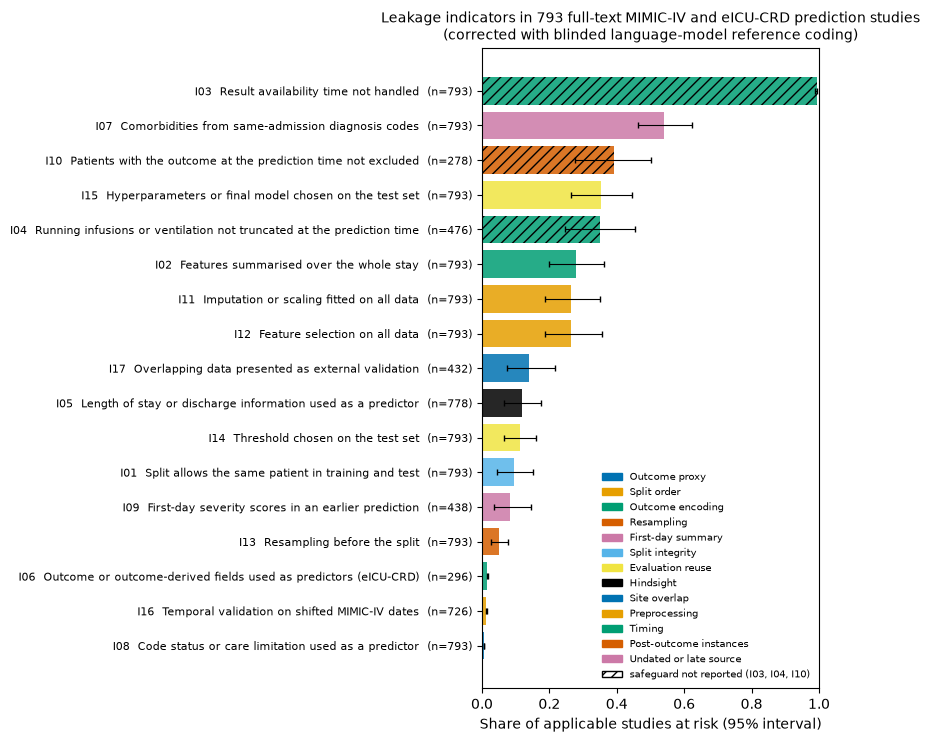

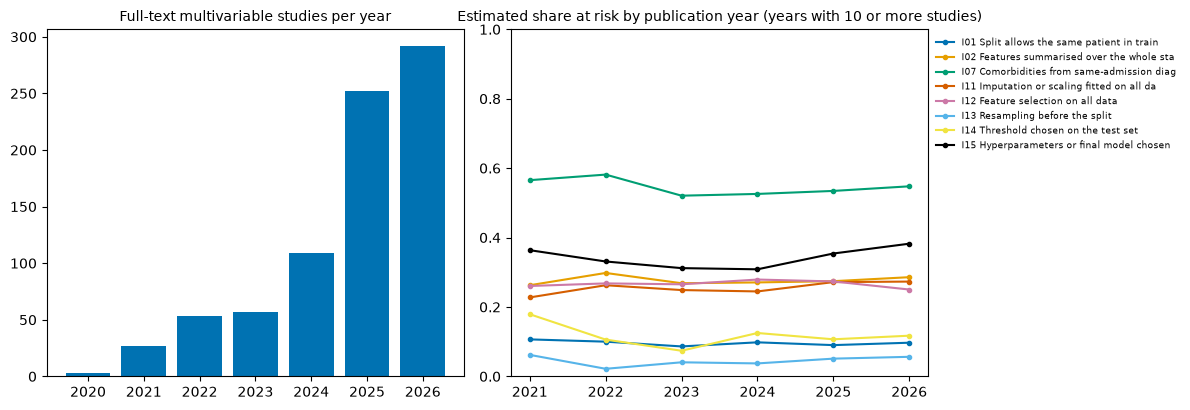

database_group,MIMIC-IV only,both,eICU-CRD only
indicator,,,
I01,0.093,0.094,0.108
I02,0.275,0.283,0.295
I03,0.991,0.995,0.995
I04,0.351,0.351,NaN
I05,0.118,0.119,0.128
I06,NaN,0.016,0.018
I07,0.560,0.526,0.446
I08,0.006,0.005,0.005
I09,0.083,0.082,0.079


,indicator,share_of_studies,n_studies
0,code_shared,0.164,793
1,code_on_request,0.016,793
2,calibration_reported,0.706,793
3,uncertainty_reported,0.830,793
4,reporting_guideline_cited,0.189,793
5,decision_curve_reported,0.610,793
6,leakage_discussed,0.198,793
7,external_validation_other_source,0.329,793
8,prediction_time_stated,0.811,793


Full-text studies 793; abstract-only studies 512


,characteristic,full_text_mean,abstract_only_mean,standardised_difference
0,publication year,2024.731,2024.748,-0.011
1,reported AUROC,0.823,0.830,-0.079
2,log sample size,7.933,8.237,-0.184
3,uses eICU-CRD,0.373,0.377,-0.008
4,mortality outcome,0.575,0.545,0.061
5,tree ensemble or deep learning,0.720,0.568,0.321
6,citations,6.573,1.904,0.459


In [13]:
pv = prevalence.sort_values("estimated_prevalence")
fig, ax = plt.subplots(figsize=(8.5, 0.36 * len(pv) + 1.4))
fams = list(dict.fromkeys(pv["family"]))
col = {f: OKABE[k % len(OKABE)] for k, f in enumerate(fams)}
y = np.arange(len(pv))
bars = ax.barh(y, pv["estimated_prevalence"], color=[col[f] for f in pv["family"]], alpha=0.85)
for b_, i_ in zip(bars, pv["indicator"]):
    if IND[i_]["kind"] == "safeguard":
        b_.set_hatch("///")
ax.errorbar(pv["estimated_prevalence"], y, xerr=[(pv["estimated_prevalence"] - pv["ci_lower"]).clip(lower=0),
                                                 (pv["ci_upper"] - pv["estimated_prevalence"]).clip(lower=0)],
            fmt="none", ecolor="black", capsize=2, lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels([f"{r.indicator}  {r.name}  (n={r.n_applicable})" for r in pv.itertuples()], fontsize=8)
ax.set_xlabel("Share of applicable studies at risk (95% interval)")
ax.set_xlim(0, 1)
ax.legend(handles=[matplotlib.patches.Patch(color=col[f], label=f) for f in fams]
          + [matplotlib.patches.Patch(facecolor="white", edgecolor="black", hatch="///", label="safeguard not reported (I03, I04, I10)")],
          fontsize=7, frameon=False, loc="lower right")
ax.set_title(f"Leakage indicators in {len(analysis):,} full-text MIMIC-IV and eICU-CRD prediction studies"
             + ("\n(corrected with blinded language-model reference coding)" if VALIDATED else "\n(screening estimates, not yet validated)"), fontsize=10)
fig.tight_layout()
save_fig(fig, "fig_prevalence")

KEY_TREND = ["I01", "I02", "I07", "I11", "I12", "I13", "I14", "I15"]
analysis["year"] = analysis["pub_year"].astype("Int64")
trend = []
for yr, g in analysis.groupby("year"):
    for i in IDS:
        app = g[g[i] != "na"]
        if len(app):
            trend.append({"year": int(yr), "indicator": i, "n": len(app), "share_risk": (app[i] == "risk").mean(),
                          "estimated": float(sum((app[i] == c).mean() * Q[i][c] for c in DEFAULT_Q))})
trend = pd.DataFrame(trend)
yearly_n = analysis.groupby("year").size().rename("full_text_studies").reset_index()
save_table(trend, "prevalence_by_year")
save_table(yearly_n, "studies_by_year")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(yearly_n["year"].astype(int), yearly_n["full_text_studies"], color=OKABE[0])
axes[0].set_title("Full-text multivariable studies per year", fontsize=10)
for k, i in enumerate(KEY_TREND):
    d = trend[(trend["indicator"] == i) & (trend["n"] >= 10)]
    axes[1].plot(d["year"], d["estimated"], marker="o", ms=3, color=OKABE[k % len(OKABE)], label=f"{i} {IND[i]['name'][:38]}")
axes[1].set_ylim(0, 1)
axes[1].set_title("Estimated share at risk by publication year (years with 10 or more studies)", fontsize=10)
axes[1].legend(fontsize=6.5, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
save_fig(fig, "fig_prevalence_trend")

by_db = []
for grp, g in analysis.groupby("database_group"):
    for i in IDS:
        app = g[g[i] != "na"]
        if len(app):
            by_db.append({"database_group": grp, "indicator": i, "n": len(app),
                          "estimated": float(sum((app[i] == c).mean() * Q[i][c] for c in DEFAULT_Q))})
by_db = pd.DataFrame(by_db).pivot_table(index="indicator", columns="database_group", values="estimated").reindex(IDS)
save_table(by_db.reset_index(), "prevalence_by_database")
display(by_db.round(3))

TCOLS = list(TRANSPARENCY) + ["external_validation_other_source", "prediction_time_stated"]
transparency = pd.DataFrame({"indicator": TCOLS, "share_of_studies": [analysis[c].mean() for c in TCOLS],
                             "n_studies": len(analysis)})
save_table(transparency, "transparency_indicators")
display(transparency.round(3))

# Representativeness: full-text studies compared with abstract-only studies
mv = papers[papers["study_type"] == "multivariable model"]


def smd(a, b):
    a, b = pd.to_numeric(a, errors="coerce").dropna(), pd.to_numeric(b, errors="coerce").dropna()
    s = np.sqrt((a.var() + b.var()) / 2)
    return (a.mean() - b.mean()) / s if s > 0 else np.nan


rep = []
ft, ab = mv[mv["text_source"] == "full text"], mv[mv["text_source"] == "abstract only"]
for name, f in [("publication year", lambda d: d["pub_year"]), ("reported AUROC", lambda d: d["reported_auroc"]),
                ("log sample size", lambda d: np.log(d["sample_size"])), ("uses eICU-CRD", lambda d: d["eicu_used"].astype(float)),
                ("mortality outcome", lambda d: (d["task"] == "mortality").astype(float)),
                ("tree ensemble or deep learning", lambda d: d["model_family"].isin(["tree ensemble", "deep learning"]).astype(float)),
                ("citations", lambda d: d["cited_by"])]:
    rep.append({"characteristic": name, "full_text_mean": pd.to_numeric(f(ft), errors="coerce").mean(),
                "abstract_only_mean": pd.to_numeric(f(ab), errors="coerce").mean(), "standardised_difference": smd(f(ft), f(ab))})
rep = pd.DataFrame(rep)
rep.attrs["n"] = (len(ft), len(ab))
save_table(rep, "representativeness_full_text_vs_abstract")
print(f"Full-text studies {len(ft):,}; abstract-only studies {len(ab):,}")
display(rep.round(3))

## 8. Do studies at risk report higher AUROC, and are they cited more?

**Content leaks** are the indicators Part 2 showed to bring outcome information in: I02, I05, I06, I07, I08 and I09.
**Procedural leaks** are I01, I11, I12, I13, I14 and I15. Both analyses use full-text multivariable studies.

* **AUROC.** Logit of the highest AUROC reported in the abstract, regressed on the two leak groups. Adjusted for
  outcome category, publication year, log sample size and model family.
* **Citations.** Log of one plus citations per year since publication, with the same adjustments.

Intervals come from 1,000 bootstrap resamples of studies. These are associations across studies, not causal effects.

{
  "studies with AUROC and sample size": 357,
  "median reported AUROC, any content leak": 0.821,
  "median reported AUROC, no content leak": 0.827,
  "difference in medians (95% CI)": [
    -0.006000000000000005,
    -0.02200000000000002,
    0.008506250000000057
  ],
  "logit AUROC coefficient, content leak": [
    -0.0691,
    -0.2205,
    0.087
  ],
  "logit AUROC coefficient, procedural leak": [
    0.0538,
    -0.0841,
    0.2033
  ],
  "studies in citation model": 793,
  "log citations per year coefficient, content leak": [
    -0.046,
    -0.1369,
    0.0456
  ]
}


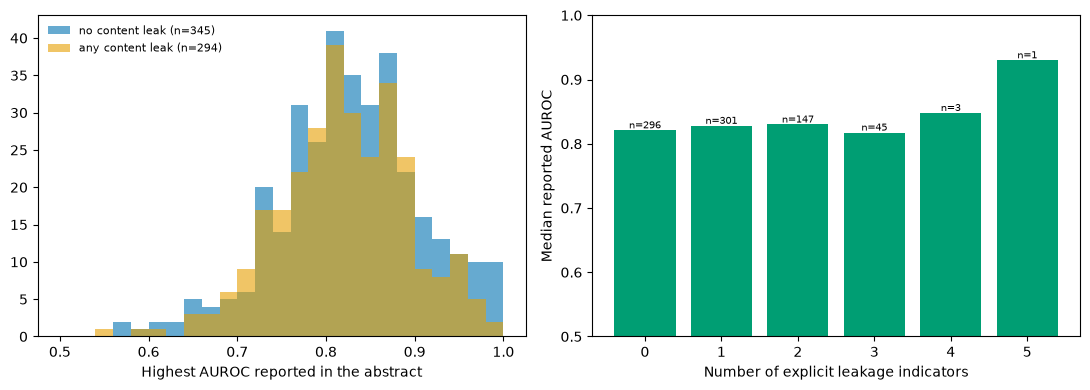

In [14]:
CONTENT = ["I02", "I05", "I06", "I07", "I08", "I09"]
PROCEDURAL = ["I01", "I11", "I12", "I13", "I14", "I15"]
analysis["any_content_risk"] = analysis[CONTENT].eq("risk").any(axis=1).astype(float)
analysis["any_procedural_risk"] = analysis[PROCEDURAL].eq("risk").any(axis=1).astype(float)
analysis["n_explicit_risk"] = analysis[CONTENT + PROCEDURAL].eq("risk").sum(axis=1)
snap_year = int(SEARCH_END[:4]) + (int(SEARCH_END[5:7]) - 0.5) / 12
analysis["years_since"] = (snap_year - pd.to_numeric(analysis["pub_year"], errors="coerce")).clip(lower=0.5)
analysis["citations_per_year"] = analysis["cited_by"] / analysis["years_since"]


def ols_boot(df, ycol, xcols, B=1000, seed=0):
    d = df.dropna(subset=[ycol] + [c for c in xcols if not c.startswith("C:")]).copy()
    cat_cols = [c[2:] for c in xcols if c.startswith("C:")]
    num_cols = [c for c in xcols if not c.startswith("C:")]
    X = pd.concat([d[num_cols]] + [pd.get_dummies(d[c].astype(str), prefix=c, drop_first=True, dtype=float) for c in cat_cols], axis=1)
    X.insert(0, "const", 1.0)
    X = X.loc[:, X.std() > 0].assign(const=1.0)
    Xv, yv = X.to_numpy(float), d[ycol].to_numpy(float)
    beta = np.linalg.lstsq(Xv, yv, rcond=None)[0]
    rb = np.random.default_rng(seed)
    bs = np.array([np.linalg.lstsq(Xv[i], yv[i], rcond=None)[0] for i in (rb.integers(0, len(yv), len(yv)) for _ in range(B))])
    out = pd.DataFrame({"term": X.columns, "estimate": beta, "ci_lower": np.quantile(bs, 0.025, axis=0),
                        "ci_upper": np.quantile(bs, 0.975, axis=0)})
    out.attrs["n"] = len(yv)
    return out


a = analysis[analysis["reported_auroc"].between(0.5, 0.999)].copy()
a["logit_auroc"] = np.log(a["reported_auroc"] / (1 - a["reported_auroc"]))
a["log_n"] = np.log(a["sample_size"])
assoc = ols_boot(a, "logit_auroc", ["any_content_risk", "any_procedural_risk", "pub_year", "log_n", "C:task", "C:model_family"],
                 seed=stable_seed("assoc"))
assoc_n = assoc.attrs["n"]
analysis["log_citations_per_year"] = np.log1p(analysis["citations_per_year"])
cit = ols_boot(analysis.assign(log_n=np.log(analysis["sample_size"])), "log_citations_per_year",
               ["any_content_risk", "any_procedural_risk", "pub_year", "C:task"], seed=stable_seed("cit"))
cit_n = cit.attrs["n"]
med = a.groupby("any_content_risk")["reported_auroc"].median()
rb = np.random.default_rng(stable_seed("median"))
g1, g0 = a.loc[a["any_content_risk"] == 1, "reported_auroc"].to_numpy(), a.loc[a["any_content_risk"] == 0, "reported_auroc"].to_numpy()
md_boot = [np.median(rb.choice(g1, len(g1))) - np.median(rb.choice(g0, len(g0))) for _ in range(1000)] if len(g1) and len(g0) else [np.nan]
assoc_summary = {
    "studies with AUROC and sample size": int(assoc_n),
    "median reported AUROC, any content leak": float(med.get(1.0, np.nan)),
    "median reported AUROC, no content leak": float(med.get(0.0, np.nan)),
    "difference in medians (95% CI)": [float(np.nanmedian(md_boot) if len(g1) and len(g0) else np.nan),
                                       float(np.nanquantile(md_boot, 0.025)), float(np.nanquantile(md_boot, 0.975))],
    "logit AUROC coefficient, content leak": assoc.set_index("term").loc["any_content_risk"].round(4).tolist() if "any_content_risk" in set(assoc["term"]) else None,
    "logit AUROC coefficient, procedural leak": assoc.set_index("term").loc["any_procedural_risk"].round(4).tolist() if "any_procedural_risk" in set(assoc["term"]) else None,
    "studies in citation model": int(cit_n),
    "log citations per year coefficient, content leak": cit.set_index("term").loc["any_content_risk"].round(4).tolist() if "any_content_risk" in set(cit["term"]) else None,
}
save_table(assoc, "association_auroc_with_leak_indicators")
save_table(cit, "association_citations_with_leak_indicators")
print(json.dumps(assoc_summary, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for k, (grp, lab) in enumerate([(0.0, "no content leak"), (1.0, "any content leak")]):
    v = a.loc[a["any_content_risk"] == grp, "reported_auroc"]
    axes[0].hist(v, bins=np.linspace(0.5, 1.0, 26), alpha=0.6, color=OKABE[k], label=f"{lab} (n={len(v)})")
axes[0].set_xlabel("Highest AUROC reported in the abstract")
axes[0].legend(fontsize=8, frameon=False)
cnt = analysis.groupby("n_explicit_risk")["reported_auroc"].agg(["median", "size"]).reset_index()
axes[1].bar(cnt["n_explicit_risk"], cnt["median"], color=OKABE[2])
for r in cnt.itertuples():
    axes[1].text(r.n_explicit_risk, r.median + 0.003, f"n={r.size}", ha="center", fontsize=7)
axes[1].set_ylim(0.5, 1.0)
axes[1].set_xlabel("Number of explicit leakage indicators")
axes[1].set_ylabel("Median reported AUROC")
fig.tight_layout()
save_fig(fig, "fig_auroc_by_leak_indicators")

## 9. Sample-size dependence of procedural leaks

Part 2 measured the procedural mechanisms on full cohorts, with 40,000 to 90,000 training stays, and found them
negligible. Published studies are often far smaller. Here each mechanism is reproduced inside simulated studies:

1. Draw a study cohort of whole patients until it has `n` ICU stays (500 to 10,000).
2. Split it 70/10/20 by patient.
3. Apply the leaky and the clean version of the step within that study, and evaluate both on the study's own test
   set, as the study would report.

Each size is repeated `SIZE_REPEATS` times for in-hospital mortality, for both databases and both models. The result is
the mean inflation a study of that size can expect. Comparisons:

* **E01b:** row-level against patient-level split.
* **E11:** imputer and scaler fitted on all study rows (logistic regression only).
* **E12:** top 30 features ranked on all study rows against training rows.
* **E13:** SMOTE before the split against inside training, on real test rows.
* **E13b:** the same, with synthetic rows kept in the test set.
* **E14:** balanced accuracy at a Youden threshold chosen on the test set against the validation set.
* **E15:** hyperparameters chosen by test AUROC against validation AUROC.

In [15]:
def sample_by_patient(df, max_stays, seed):
    if not max_stays or len(df) <= max_stays:
        return df
    pats = df["patient_id"].drop_duplicates().sample(frac=1.0, random_state=seed)
    counts = df.groupby("patient_id").size().reindex(pats).cumsum()
    keep = set(counts[counts <= max_stays].index)
    return df[df["patient_id"].isin(keep)].copy()


def make_model(name, **kw):
    if name == "logistic":
        return Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler()),
                         ("clf", LogisticRegression(C=kw.get("C", 1.0), max_iter=3000))])
    if name == "hgb":
        return HistGradientBoostingClassifier(learning_rate=kw.get("lr", 0.05), max_leaf_nodes=kw.get("leaves", 31),
                                              max_iter=kw.get("iters", 250), l2_regularization=1.0, early_stopping=False,
                                              random_state=SEED)
    raise ValueError(name)


def fit_predict(name, X, y, train_mask, **kw):
    # Predictors with no observed value in the training rows carry no information (and break histogram binning)
    keep = np.isfinite(X[train_mask]).any(axis=0)
    Xk = X[:, keep]
    m = make_model(name, **kw)
    m.fit(Xk[train_mask], y[train_mask])
    return m.predict_proba(Xk)[:, 1], m


def design(c, *blocks):
    X = pd.concat([c[["age", "female"]]] + [b.reindex(c.index) for b in blocks], axis=1)
    X = X.loc[:, ~X.columns.duplicated()]
    return X.apply(pd.to_numeric, errors="coerce").astype("float64")


def univariate_auc(X, y):
    out = {}
    for j in range(X.shape[1]):
        x = X[:, j]
        ok = np.isfinite(x)
        if ok.sum() < 30 or len(np.unique(y[ok])) < 2:
            continue
        a_ = ilc.auroc(y[ok], x[ok])
        out[j] = max(a_, 1 - a_)
    return pd.Series(out, dtype=float).sort_values(ascending=False)


def smote(X, y, k, seed):
    rng_ = np.random.default_rng(seed)
    minority = 1 if (y == 1).sum() < (y == 0).sum() else 0
    Xm = X[y == minority]
    n_new = int((y != minority).sum() - (y == minority).sum())
    if n_new <= 0 or len(Xm) <= k:
        return np.empty((0, X.shape[1])), np.empty(0)
    sd = Xm.std(axis=0)
    sd[sd == 0] = 1
    nn = NearestNeighbors(n_neighbors=k + 1).fit(Xm / sd)
    _, ind = nn.kneighbors(Xm / sd)
    base = rng_.integers(0, len(Xm), n_new)
    neigh = ind[base, rng_.integers(1, k + 1, n_new)]
    lam = rng_.random((n_new, 1))
    return Xm[base] + lam * (Xm[neigh] - Xm[base]), np.full(n_new, minority)


def balanced_accuracy(y, p, t):
    pred = p >= t
    sens = np.sum(pred & (y == 1)) / max(np.sum(y == 1), 1)
    spec = np.sum(~pred & (y == 0)) / max(np.sum(y == 0), 1)
    return (sens + spec) / 2


LOCAL = {}
for db in ("mimic-iv", "eicu"):
    c = pd.read_parquet(P1_DATA / f"cohort_{db}.parquet")
    c = sample_by_patient(c, MAX_STAYS, SEED).set_index("stay_id")
    Fc = pd.read_parquet(P1_DATA / f"features_clean_24h_{db}.parquet").set_index("entity_id").reindex(c.index)
    X = design(c, Fc)
    codes, uniq = pd.factorize(c["patient_id"])
    order = np.argsort(codes, kind="mergesort")
    starts = np.searchsorted(codes[order], np.arange(len(uniq)))
    ends = np.r_[starts[1:], len(codes)]
    LOCAL[db] = {"c": c, "X": X.to_numpy(), "cols": list(X.columns), "y": c["mortality"].astype(int).to_numpy(),
                 "order": order, "starts": starts, "ends": ends}
    print(f"{LABEL[db]}: {len(c):,} stays, {len(uniq):,} patients, {X.shape[1]} predictors")

MIMIC-IV: 57,460 stays, 42,067 patients, 100 predictors
eICU-CRD: 129,258 stays, 102,154 patients, 98 predictors


In [16]:
GRID = {"logistic": [{"C": v} for v in (0.001, 0.01, 0.1, 1.0, 10.0)],
        "hgb": [{"lr": 0.05, "leaves": 15}, {"lr": 0.1, "leaves": 31}, {"lr": 0.05, "leaves": 63}]}


def draw_study(L, size, rng_):
    perm = rng_.permutation(len(L["starts"]))
    lens = (L["ends"] - L["starts"])[perm]
    k = int(np.searchsorted(np.cumsum(lens), size) + 1)
    chosen = perm[:k]
    rows = np.concatenate([L["order"][L["starts"][p]:L["ends"][p]] for p in chosen])
    pat_of_row = np.concatenate([np.full(L["ends"][p] - L["starts"][p], j) for j, p in enumerate(chosen)])
    u = rng_.random(k)
    part = np.where(u < 0.7, 0, np.where(u < 0.8, 1, 2))[pat_of_row]
    return rows, part


def one_study(db, model, size, rep):
    L = LOCAL[db]
    rng_ = np.random.default_rng(stable_seed("size", db, model, size, rep))
    for _ in range(20):
        rows, part = draw_study(L, size, rng_)
        y = L["y"][rows]
        tr, va, te = part == 0, part == 1, part == 2
        r = rng_.random(len(rows))
        rtr, rte = r < 0.7, r >= 0.8
        if all(len(np.unique(y[m])) == 2 and y[m].sum() >= 3 for m in (tr, va, te, rtr, rte)):
            break
    else:
        return []
    X = L["X"][rows]
    out = []

    def rec(mech, clean, leaky, metric="auroc"):
        out.append({"database": db, "model": model, "size": size, "repeat": rep, "n_stays": len(rows),
                    "n_test": int(te.sum()), "n_test_events": int(y[te].sum()), "mechanism": mech, "metric": metric,
                    "clean": clean, "leaky": leaky, "difference": leaky - clean})

    p0, _ = fit_predict(model, X, y, tr)
    a0 = ilc.auroc(y[te], p0[te])
    p_row, _ = fit_predict(model, X, y, rtr)
    rec("E01b", a0, ilc.auroc(y[rte], p_row[rte]))
    if model == "logistic":
        pre = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]).fit(X)
        clf = LogisticRegression(C=1.0, max_iter=3000).fit(pre.transform(X[tr]), y[tr])
        rec("E11", a0, ilc.auroc(y[te], clf.predict_proba(pre.transform(X[te]))[:, 1]))
    sel_all = univariate_auc(X, y).index[:TOP_K_FEATURES].to_numpy()
    sel_tr = univariate_auc(X[tr], y[tr]).index[:TOP_K_FEATURES].to_numpy()
    p_tr, _ = fit_predict(model, X[:, sel_tr], y, tr)
    p_all, _ = fit_predict(model, X[:, sel_all], y, tr)
    rec("E12", ilc.auroc(y[te], p_tr[te]), ilc.auroc(y[te], p_all[te]))
    med = np.nanmedian(X[tr], axis=0)
    Xi = np.where(np.isnan(X), np.nan_to_num(med), X)
    s_seed = stable_seed("smote", db, model, size, rep)
    Xs_tr, ys_tr = smote(Xi[tr], y[tr], SMOTE_K, s_seed)
    m_in = make_model(model).fit(np.vstack([Xi[tr], Xs_tr]), np.r_[y[tr], ys_tr])
    Xs_all, ys_all = smote(Xi, y, SMOTE_K, s_seed + 1)
    asg = np.random.default_rng(s_seed + 2).random(len(ys_all))
    m_bef = make_model(model).fit(np.vstack([Xi[tr], Xs_all[asg < 0.7]]), np.r_[y[tr], ys_all[asg < 0.7]])
    a_in = ilc.auroc(y[te], m_in.predict_proba(Xi[te])[:, 1])
    rec("E13", a_in, ilc.auroc(y[te], m_bef.predict_proba(Xi[te])[:, 1]))
    Xrep, yrep = np.vstack([Xi[te], Xs_all[asg >= 0.8]]), np.r_[y[te], ys_all[asg >= 0.8]]
    rec("E13b", a_in, ilc.auroc(yrep, m_bef.predict_proba(Xrep)[:, 1]))
    t_v, t_t = ilc.metrics.youden_threshold(y[va], p0[va]), ilc.metrics.youden_threshold(y[te], p0[te])
    rec("E14", balanced_accuracy(y[te], p0[te], t_v), balanced_accuracy(y[te], p0[te], t_t), metric="balanced_accuracy")
    preds = [fit_predict(model, X, y, tr, **g)[0] for g in GRID[model]]
    bv = int(np.argmax([ilc.auroc(y[va], q[va]) for q in preds]))
    test_aucs = [ilc.auroc(y[te], q[te]) for q in preds]
    rec("E15", test_aucs[bv], max(test_aucs))
    return out


size_results = []
for db in ("mimic-iv", "eicu"):
    for model in MODELS:
        for size in SIZES:
            f = RAW_DIR / f"size_{db}_{model}_{size}.parquet"
            if RESUME and f.exists() and len(pd.read_parquet(f)["repeat"].unique()) >= SIZE_REPEATS:
                size_results.append(pd.read_parquet(f))
                continue
            t0 = time.time()
            res = [row for rep in range(SIZE_REPEATS) for row in one_study(db, model, size, rep)]
            df = pd.DataFrame(res)
            df.to_parquet(f, index=False)
            size_results.append(df)
            print(f"{LABEL[db]:9s} {model:9s} n={size:>6,}: {df['repeat'].nunique()} studies ({(time.time() - t0) / 60:.1f} min)")
size_results = pd.concat(size_results, ignore_index=True)
size_summary = (size_results.groupby(["database", "model", "size", "mechanism", "metric"])
                .agg(studies=("difference", "size"), mean_clean=("clean", "mean"), mean_difference=("difference", "mean"),
                     sd_difference=("difference", "std"), q025=("difference", lambda s: s.quantile(0.025)),
                     q975=("difference", lambda s: s.quantile(0.975)), share_inflated=("difference", lambda s: (s > 0).mean()))
                .reset_index())
size_summary["se"] = size_summary["sd_difference"] / np.sqrt(size_summary["studies"])
save_table(size_summary, "size_dependence")
display(size_summary[size_summary["database"] == "mimic-iv"].pivot_table(index=["mechanism", "model"], columns="size", values="mean_difference").round(3))

size                500    1000   2000   5000   10000
mechanism model                                      
E01b      hgb       0.031  0.015  0.015  0.000  0.007
          logistic  0.020 -0.017  0.007  0.001 -0.002
E11       logistic  0.004  0.004 -0.000  0.001  0.000
E12       hgb       0.022  0.001  0.002  0.001  0.003
          logistic  0.034  0.006  0.005  0.003  0.001
E13       hgb       0.156  0.148  0.140  0.088  0.057
          logistic  0.207  0.132  0.081  0.038  0.018
E13b      hgb       0.197  0.180  0.176  0.144  0.134
          logistic  0.238  0.136  0.091  0.051  0.024
E14       hgb       0.082  0.044  0.036  0.016  0.012
          logistic  0.080  0.070  0.031  0.018  0.017
E15       hgb       0.004  0.007  0.006  0.003  0.002
          logistic  0.041  0.032  0.012  0.008  0.003

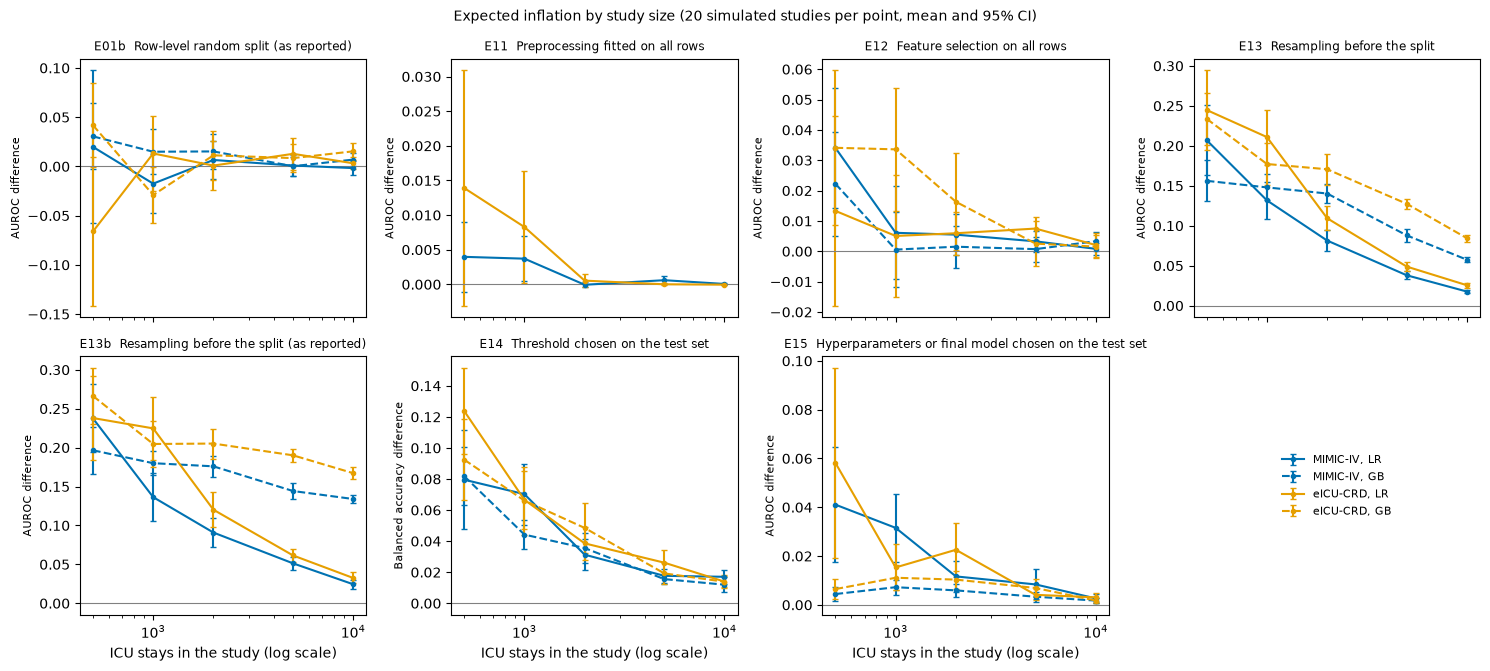

In [17]:
SIZE_MECHS = ["E01b", "E11", "E12", "E13", "E13b", "E14", "E15"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.8), sharex=True)
for ax, mech in zip(axes.ravel(), SIZE_MECHS):
    for k, db in enumerate(("mimic-iv", "eicu")):
        for model, ls in (("logistic", "-"), ("hgb", "--")):
            d = size_summary[(size_summary["database"] == db) & (size_summary["model"] == model) & (size_summary["mechanism"] == mech)]
            if d.empty:
                continue
            ax.errorbar(d["size"], d["mean_difference"], yerr=1.96 * d["se"], ls=ls, marker="o", ms=3, capsize=2,
                        color=OKABE[k], label=f"{LABEL[db]}, {'LR' if model == 'logistic' else 'GB'}")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xscale("log")
    ax.set_title(f"{mech}  {MECH[mech][0]}", fontsize=8.5)
    ax.set_ylabel("Balanced accuracy difference" if mech == "E14" else "AUROC difference", fontsize=8)
axes.ravel()[-1].axis("off")
h, l = axes.ravel()[0].get_legend_handles_labels()
axes.ravel()[-1].legend(h, l, fontsize=8, frameon=False, loc="center")
for ax in axes[1]:
    ax.set_xlabel("ICU stays in the study (log scale)")
fig.suptitle(f"Expected inflation by study size ({SIZE_REPEATS} simulated studies per point, mean and 95% CI)", fontsize=10)
fig.tight_layout()
save_fig(fig, "fig_size_dependence")

## 10. Do leaks add up?

Published pipelines often combine several leaks. This section switches on the three most common content leaks
together, for in-hospital mortality on the full cohorts:

* look-ahead features (E02);
* same-admission codes (E07);
* care limitation or code status at any time (E08).

The combined inflation is then compared with the sum of the three single-leak inflations. The ratio of the two (combined
over sum) is the additivity factor that the field-level model in Section 11 uses. It is estimated with a paired
patient-level bootstrap.

In [18]:
POINT_AGGS, CUMULATIVE_AGGS = ("last", "min", "max", "mean"), ("sum", "count")
CUMULATIVE = {"urine_output", "norepinephrine", "epinephrine", "vasopressin", "phenylephrine", "dopamine", "dobutamine",
              "invasive_ventilation", "noninvasive_ventilation", "mech_vent_documented"}


def make_features(ev, entity_ids, index_times, window, cutoff, time_basis, interval_policy, min_present=0.01):
    idx = pd.DataFrame({"entity_id": np.asarray(entity_ids), "index_time": np.asarray(index_times, dtype="float64")})
    feats = []
    lower = float(idx["index_time"].min()) - window
    for var in sorted(ev["variable"].astype(str).unique()):
        sub = ev[ev["variable"] == var]
        sub = sub[(sub["event_time"] > lower) | (sub["end_time"].notna() & (sub["end_time"] > lower))]
        if sub.empty:
            continue
        sub = sub.assign(variable=var).astype({"value": "float64", "event_time": "float64", "available_time": "float64", "end_time": "float64"})
        aggs = CUMULATIVE_AGGS if var in CUMULATIVE else POINT_AGGS
        feats.append(ilc.build_window_features(sub, idx, window=window, aggregations=aggs, time_basis=time_basis,
                                               cutoff=cutoff, interval_policy=interval_policy))
    F = pd.concat(feats, axis=1)
    return F.loc[:, F.notna().mean() >= min_present]


def boot_groups(groups, seed, n_boot):
    codes_, uniq_ = pd.factorize(pd.Series(groups))
    order_ = np.argsort(codes_, kind="mergesort")
    st = np.searchsorted(codes_[order_], np.arange(len(uniq_)))
    en = np.r_[st[1:], len(codes_)]
    rg = np.random.default_rng(seed)
    for _ in range(n_boot):
        pick = rg.integers(0, len(uniq_), len(uniq_))
        yield np.concatenate([order_[st[k]:en[k]] for k in pick])


comb_rows = []
for db in ("mimic-iv", "eicu"):
    f = RAW_DIR / f"combination_{db}.parquet"
    if RESUME and f.exists():
        comb_rows.append(pd.read_parquet(f))
        continue
    t0 = time.time()
    c = LOCAL[db]["c"]
    ids = c.index.to_numpy()
    if MAX_STAYS:
        ev = pd.read_parquet(P1_DATA / f"events_{db}.parquet", filters=[("entity_id", "in", ids.tolist())])
    else:
        ev = pd.read_parquet(P1_DATA / f"events_{db}.parquet")
    Fc = pd.read_parquet(P1_DATA / f"features_clean_24h_{db}.parquet").set_index("entity_id").reindex(ids)
    Fl = make_features(ev, ids, c["index_time"], INDEX_MIN, "none", "event", "keep")
    del ev
    h = pd.read_parquet(P1_DATA / f"hindsight_{db}.parquet").set_index("stay_id").reindex(ids)
    if db == "mimic-iv":
        billing = h[["dx_same_adm_count", "dx_same_adm_proxy", "dx_same_adm_dnr", "dx_same_adm_palliative", "drg_severity", "drg_mortality"]]
        proxy = pd.DataFrame({"code_status_limitation_any": h["code_limitation_any"]})
    else:
        billing = h[["dx_count_all", "dx_active_at_discharge"]]
        proxy = pd.DataFrame({"care_limitation_any": h["care_limitation_any"], "end_of_life_discussion_any": h["eol_any"]})
    variants = {"clean": design(c, Fc), "E02": design(c, Fl), "E07": design(c, Fc, billing), "E08": design(c, Fc, proxy),
                "combined": design(c, Fl, billing, proxy)}
    y = c["mortality"].astype(int).to_numpy()
    split = c["split_patient"].to_numpy()
    tr, te = split == "train", split == "test"
    g = c["patient_id"].to_numpy()[te]
    for model in MODELS:
        P_ = {k: fit_predict(model, v.to_numpy(), y, tr)[0][te] for k, v in variants.items()}
        yt = y[te]
        point = {k: ilc.auroc(yt, p) for k, p in P_.items()}
        reps = []
        for ib in boot_groups(g, stable_seed("comb", db, model), N_BOOT):
            a_ = {k: ilc.auroc(yt[ib], p[ib]) for k, p in P_.items()}
            d = {k: a_[k] - a_["clean"] for k in ("E02", "E07", "E08", "combined")}
            s = d["E02"] + d["E07"] + d["E08"]
            reps.append({**d, "sum": s, "ratio": d["combined"] / s if s > 0.005 else np.nan})
        R = pd.DataFrame(reps)
        dp = {k: point[k] - point["clean"] for k in ("E02", "E07", "E08", "combined")}
        sp = dp["E02"] + dp["E07"] + dp["E08"]
        row = {"database": db, "model": model, "clean_auroc": point["clean"], **{f"delta_{k}": v for k, v in dp.items()},
               "delta_sum": sp, "ratio": dp["combined"] / sp if sp > 0.005 else np.nan,
               "ratio_lower": R["ratio"].quantile(0.025), "ratio_upper": R["ratio"].quantile(0.975),
               "ratio_se": R["ratio"].std(), "combined_lower": R["combined"].quantile(0.025), "combined_upper": R["combined"].quantile(0.975)}
        comb_rows.append(pd.DataFrame([row]))
    pd.concat(comb_rows[-len(MODELS):], ignore_index=True).to_parquet(f, index=False)
    print(f"{LABEL[db]}: combination experiment finished ({(time.time() - t0) / 60:.1f} min)")
combination = pd.concat(comb_rows, ignore_index=True)
save_table(combination, "combination_additivity")
ADDITIVITY = float(np.nanmean(combination["ratio"]))
ADDITIVITY_SE = float(np.sqrt(np.nanmean(combination["ratio_se"] ** 2)) / max(np.isfinite(combination["ratio"]).sum(), 1) ** 0.5)
if not np.isfinite(ADDITIVITY):
    ADDITIVITY, ADDITIVITY_SE = 1.0, 0.0
print(f"Additivity factor (combined inflation / sum of single inflations): {ADDITIVITY:.3f} (SE {ADDITIVITY_SE:.3f})")
display(combination.round(4))

Additivity factor (combined inflation / sum of single inflations): 0.777 (SE 0.010)


,database,model,clean_auroc,delta_E02,delta_E07,delta_E08,delta_combined,delta_sum,ratio,ratio_lower,ratio_upper,ratio_se,combined_lower,combined_upper
0,mimic-iv,logistic,0.8676,0.0346,0.0715,0.0120,0.0858,0.1180,0.7272,0.6936,0.7585,0.0167,0.0774,0.0950
1,mimic-iv,hgb,0.8854,0.0310,0.0608,0.0107,0.0761,0.1025,0.7424,0.7066,0.7875,0.0217,0.0676,0.0856
2,eicu,logistic,0.8403,0.0329,0.0010,0.0448,0.0619,0.0787,0.7865,0.7586,0.8096,0.0135,0.0546,0.0691
3,eicu,hgb,0.8643,0.0270,0.0136,0.0355,0.0650,0.0762,0.8529,0.8126,0.9027,0.0241,0.0590,0.0716


## 11. Field-level optimism

For each full-text multivariable study with a reported AUROC, the expected optimism is the sum, over its indicators, of
the probability that the indicator is truly at risk multiplied by the AUROC inflation of the matching mechanism. That
sum is then scaled by the additivity factor. The inputs come from:

* **Probability truly at risk:** Section 6 (validated), or 1 for `risk` and 0.5 for `unclear` before validation.
* **Inflation:** Part 2, matched on outcome (mortality, prolonged stay or AKI; the mean of the three otherwise), model
  family (regression to logistic regression, other families to gradient boosting) and database. Procedural mechanisms
  use the Section 9 value for the study's sample size.
* **Not included:** I14 (threshold, not AUROC), I16 (misestimation in either direction) and I17 (not measurable here).

The Monte Carlo model draws, `N_MC` times:
* each study's true indicator status;
* each inflation from its sampling distribution, shared across studies;
* the additivity factor.

Optimism is capped so that no adjusted AUROC falls below 0.5. The output is an expected value for the field, not a
verdict on any single paper.

,quantity,estimate,lower_95,upper_95
0,mean_optimism,0.0620,0.0557,0.0686
1,median_optimism,0.0519,0.0451,0.0585
2,share_over_0.01,0.7934,0.7574,0.8326
3,share_over_0.05,0.5243,0.4319,0.5790
4,share_of_0.90_claims_remaining,0.4211,0.3263,0.5053
5,mean_adjusted_auroc,0.7610,0.7544,0.7673
6,mean reported AUROC,0.8230,NaN,NaN
7,studies in the model,639.0000,NaN,NaN
8,studies reporting AUROC >= 0.90,95.0000,NaN,NaN


,task,studies,mean_reported,mean_expected_optimism,median_expected_optimism
0,aki,79,0.8277,0.0723,0.0687
1,bleeding or thrombosis,31,0.8401,0.0743,0.0656
2,circulatory,16,0.8313,0.0801,0.0761
3,delirium,11,0.7990,0.0939,0.0863
4,los,14,0.8001,0.0540,0.0522
5,mortality,351,0.8180,0.0539,0.0486
6,other,30,0.8635,0.0447,0.0395
7,readmission,5,0.7482,0.0612,0.0548
8,respiratory,41,0.8241,0.0776,0.0713
9,sepsis,61,0.8304,0.0793,0.0756


,indicator,mechanism,mean_contribution
6,I07,E07,0.0169
1,I02,E02,0.0139
4,I05,E05,0.0097
9,I10,E10b,0.0080
12,I13,E13b,0.0062
2,I03,E03,0.0020
13,I15,E15,0.0014
8,I09,E09,0.0014
11,I12,E12,0.0011
3,I04,E04,0.0006


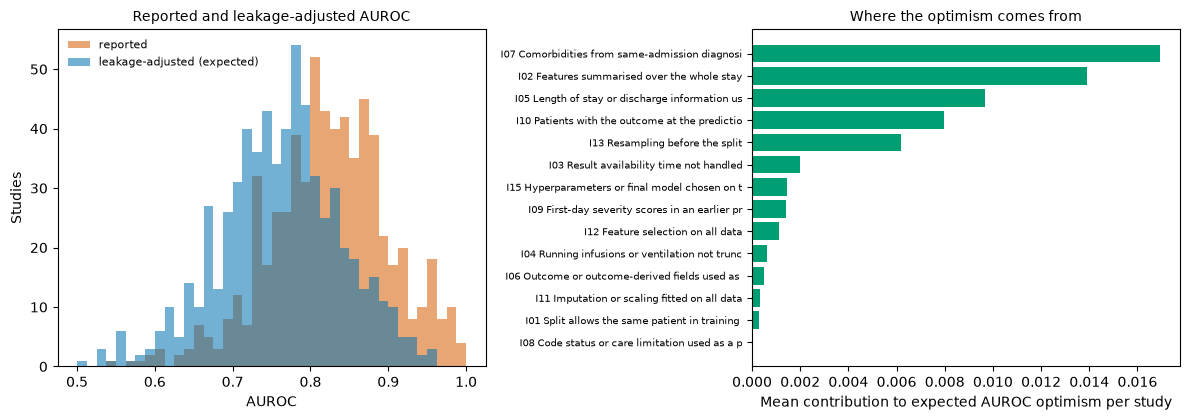

In [19]:
p2 = pd.read_csv(P2 / "results" / "tables" / "inflation_all.csv")
p2 = p2[(p2["metric"] == "auroc") & (p2["mechanism"] != "E00")].copy()
AS_REPORTED = {"E01b", "E10b", "E13b", "E16", "E17"}
p2 = p2[np.where(p2["mechanism"].isin(AS_REPORTED), p2["comparison"] == "as reported", p2["comparison"] == "paired")]
p2["se"] = (p2["diff_upper"] - p2["diff_lower"]) / 3.92
P2LOOK = {(r.mechanism, r.task, r.model, r.database): (r.difference, r.se) for r in p2.itertuples()}
SIZELOOK = {(r.mechanism, r.model, r.database, r.size): (r.mean_difference, r.se)
            for r in size_summary[size_summary["metric"] == "auroc"].itertuples()}
SIZE_DEP = {"E01b", "E11", "E12", "E13b", "E15"}
MC_IND = [i for i in IDS if i not in ("I14", "I16", "I17")]
TASK_MAP = {"mortality": ["mortality"], "los": ["long_stay"], "aki": ["aki"]}


def inflation(mech, task, model, dbs, n):
    tasks = TASK_MAP.get(task, ["mortality", "long_stay", "aki"])
    if mech == "E10b" and task not in ("aki",):
        tasks = ["aki"]
    dbs = [d for d in ("mimic-iv", "eicu") if d in dbs] or ["mimic-iv", "eicu"]
    vals = []
    for d in dbs:
        if mech in SIZE_DEP and np.isfinite(n) and n <= max(SIZES):
            s = max([s_ for s_ in SIZES if s_ <= n] or [min(SIZES)])
            v = SIZELOOK.get((mech, model, d, s))
            if v is None and mech == "E11":
                v = SIZELOOK.get((mech, "logistic", d, s))
            if v is not None:
                vals.append(v)
                continue
        for t in tasks:
            v = P2LOOK.get((mech, t, model, d)) or P2LOOK.get((mech, t, "logistic", d))
            if v is not None:
                vals.append(v)
    if not vals:
        for d2 in ("mimic-iv", "eicu"):
            for t in tasks:
                v = P2LOOK.get((mech, t, model, d2))
                if v is not None:
                    vals.append(v)
    if not vals:
        return 0.0, 0.0
    m = np.array(vals, float)
    return float(np.nanmean(m[:, 0])), float(np.sqrt(np.nanmean(m[:, 1] ** 2)))


fo = analysis[analysis["reported_auroc"].between(0.5, 1.0)].copy()
fo["p2_model"] = np.where(fo["model_family"] == "regression", "logistic", "hgb")
Pn, J = len(fo), len(MC_IND)
Qm, Dm, Ds = np.zeros((Pn, J)), np.zeros((Pn, J)), np.zeros((Pn, J))
for j, i in enumerate(MC_IND):
    mech = IND[i]["mechanism"]
    vals = fo[i].to_numpy()
    Qm[:, j] = [Q[i].get(v, 0.0) if v != "na" else 0.0 for v in vals]
    for r_, row in enumerate(fo.itertuples()):
        Dm[r_, j], Ds[r_, j] = inflation(mech, row.task, row.p2_model, row.databases.split(";"), row.sample_size)
reported = fo["reported_auroc"].to_numpy()
cap = np.clip(reported - 0.5, 0, None)
rg = np.random.default_rng(stable_seed("mc"))
draws, per_paper = [], np.zeros(Pn)
for _ in range(N_MC):
    flags = rg.random((Pn, J)) < Qm
    delta = Dm + Ds * rg.standard_normal(J)
    factor = max(0.0, ADDITIVITY + ADDITIVITY_SE * rg.standard_normal())
    tot = np.minimum(factor * (flags * delta).sum(axis=1), cap)
    adj = reported - tot
    per_paper += tot / N_MC
    hi = reported >= 0.90
    draws.append({"mean_optimism": tot.mean(), "median_optimism": np.median(tot), "share_over_0.01": (tot > 0.01).mean(),
                  "share_over_0.05": (tot > 0.05).mean(),
                  "share_of_0.90_claims_remaining": ((adj >= 0.90) & hi).sum() / max(hi.sum(), 1),
                  "mean_adjusted_auroc": adj.mean()})
draws = pd.DataFrame(draws)
fo["expected_optimism"] = per_paper
fo["adjusted_auroc"] = reported - per_paper
field = pd.DataFrame({"quantity": draws.columns, "estimate": draws.median().values,
                      "lower_95": draws.quantile(0.025).values, "upper_95": draws.quantile(0.975).values})
field.loc[len(field)] = ["mean reported AUROC", reported.mean(), np.nan, np.nan]
field.loc[len(field)] = ["studies in the model", Pn, np.nan, np.nan]
field.loc[len(field)] = ["studies reporting AUROC >= 0.90", int((reported >= 0.90).sum()), np.nan, np.nan]
save_table(field, "field_optimism")
by_task = fo.groupby("task").agg(studies=("expected_optimism", "size"), mean_reported=("reported_auroc", "mean"),
                                 mean_expected_optimism=("expected_optimism", "mean"),
                                 median_expected_optimism=("expected_optimism", "median")).reset_index()
save_table(by_task, "field_optimism_by_task")
contrib = pd.DataFrame({"indicator": MC_IND, "mechanism": [IND[i]["mechanism"] for i in MC_IND],
                        "mean_contribution": (Qm * Dm).mean(axis=0) * ADDITIVITY})
contrib = contrib.sort_values("mean_contribution", ascending=False)
save_table(contrib, "field_optimism_contributions")
fo[["paper_key", "task", "model_family", "databases", "sample_size", "reported_auroc", "expected_optimism", "adjusted_auroc"]].to_csv(
    PRIVATE_DIR / "paper_level_expected_optimism.csv", index=False)
display(field.round(4))
display(by_task.round(4))
display(contrib.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
bins = np.linspace(0.5, 1.0, 41)
axes[0].hist(reported, bins=bins, alpha=0.55, color=OKABE[3], label="reported")
axes[0].hist(fo["adjusted_auroc"], bins=bins, alpha=0.55, color=OKABE[0], label="leakage-adjusted (expected)")
axes[0].set_xlabel("AUROC")
axes[0].set_ylabel("Studies")
axes[0].legend(fontsize=8, frameon=False)
axes[0].set_title("Reported and leakage-adjusted AUROC", fontsize=10)
axes[1].barh([f"{r.indicator} {IND[r.indicator]['name'][:42]}" for r in contrib.itertuples()][::-1],
             contrib["mean_contribution"].to_numpy()[::-1], color=OKABE[2])
axes[1].set_xlabel("Mean contribution to expected AUROC optimism per study")
axes[1].tick_params(axis="y", labelsize=7)
axes[1].set_title("Where the optimism comes from", fontsize=10)
fig.tight_layout()
save_fig(fig, "fig_field_optimism")

In [20]:
# Sensitivity: explicitly described practices only (safeguard indicators I03, I04, I10 left out)
keep_j = [j for j, i in enumerate(MC_IND) if IND[i]["kind"] != "safeguard"]
rg2 = np.random.default_rng(stable_seed("mc_explicit"))
d2 = []
for _ in range(N_MC):
    flags = rg2.random((Pn, len(keep_j))) < Qm[:, keep_j]
    delta = Dm[:, keep_j] + Ds[:, keep_j] * rg2.standard_normal(len(keep_j))
    factor = max(0.0, ADDITIVITY + ADDITIVITY_SE * rg2.standard_normal())
    tot = np.minimum(factor * (flags * delta).sum(axis=1), cap)
    adj, hi = reported - tot, reported >= 0.90
    d2.append({"mean_optimism": tot.mean(), "median_optimism": np.median(tot), "share_over_0.01": (tot > 0.01).mean(),
               "share_over_0.05": (tot > 0.05).mean(),
               "share_of_0.90_claims_remaining": ((adj >= 0.90) & hi).sum() / max(hi.sum(), 1),
               "mean_adjusted_auroc": adj.mean()})
d2 = pd.DataFrame(d2)
field_explicit = pd.DataFrame({"quantity": d2.columns, "estimate": d2.median().values,
                               "lower_95": d2.quantile(0.025).values, "upper_95": d2.quantile(0.975).values})
save_table(field_explicit, "field_optimism_explicit_practices_only")
display(field_explicit.round(4))

,quantity,estimate,lower_95,upper_95
0,mean_optimism,0.0516,0.0461,0.0572
1,median_optimism,0.0334,0.0272,0.0454
2,share_over_0.01,0.7340,0.6948,0.7715
3,share_over_0.05,0.3991,0.3365,0.4820
4,share_of_0.90_claims_remaining,0.5053,0.4105,0.6000
5,mean_adjusted_auroc,0.7715,0.7658,0.7770


In [21]:
# Sensitivity of projected optimism to the modelling assumptions.
# When the validation sheet is coded, the probability that a study is truly at risk is drawn in every iteration from
# Beta(x + 0.5, n - x + 0.5) for its automated category, so the intervals also carry the uncertainty of the validation.
CATS = ["risk", "unclear", "safe", "not_mentioned"]
cat_idx = np.full((Pn, J), -1)
for j, i in enumerate(MC_IND):
    cat_idx[:, j] = [CATS.index(v) if v in CATS else -1 for v in fo[i].to_numpy()]
beta_a = np.zeros((J, 4)); beta_b = np.zeros((J, 4)); fixed_q = np.zeros((J, 4))
for j, i in enumerate(MC_IND):
    for k, c in enumerate(CATS):
        fixed_q[j, k] = Q[i].get(c, 0.0)
        if VALIDATED:
            _, n_c, x_c = q_table(reference, i)[0][c]
            beta_a[j, k], beta_b[j, k] = x_c + 0.5, n_c - x_c + 0.5
CONTENT = {"I02", "I05", "I06", "I07", "I08", "I09"}


def draw_q(rg, unclear=None):
    qd = fixed_q.copy()
    if VALIDATED:
        has = (beta_a + beta_b) > 1.0          # categories with at least one coded study
        qd[has] = rg.beta(beta_a[has], beta_b[has])
    if unclear is not None:
        qd[:, 1] = unclear
    qp = np.where(cat_idx >= 0, qd[np.arange(J)[None, :], np.clip(cat_idx, 0, 3)], 0.0)
    return qp


def scenario(name, keep, factor="estimated", combine="sum", unclear=None):
    keep = np.array(keep)
    rg_s = np.random.default_rng(stable_seed("sensitivity", name))
    out = []
    for _ in range(N_MC):
        qp = draw_q(rg_s, unclear)[:, keep]
        flags = rg_s.random(qp.shape) < qp
        delta = Dm[:, keep] + Ds[:, keep] * rg_s.standard_normal(len(keep))
        f = max(0.0, ADDITIVITY + ADDITIVITY_SE * rg_s.standard_normal()) if factor == "estimated" else factor
        tot = f * (flags * delta).sum(axis=1) if combine == "sum" else np.clip(flags * delta, 0, None).max(axis=1)
        tot = np.minimum(tot, cap)
        adj, hi = reported - tot, reported >= 0.90
        out.append([tot.mean(), np.median(tot), (tot > 0.05).mean(), ((adj >= 0.90) & hi).sum() / max(hi.sum(), 1), adj.mean()])
    o = np.array(out)
    med, lo, up = np.median(o, axis=0), np.quantile(o, 0.025, axis=0), np.quantile(o, 0.975, axis=0)
    fmt = lambda k, pct=False: (f"{100*med[k]:.1f} ({100*lo[k]:.1f} to {100*up[k]:.1f})" if pct else f"{med[k]:.3f} ({lo[k]:.3f} to {up[k]:.3f})")
    return {"Scenario": name, "Mean optimism (95% interval)": fmt(0), "Median optimism": fmt(1), "Studies > 0.05, %": fmt(2, True),
            "AUROC ≥ 0.90 claims remaining, %": fmt(3, True), "Mean adjusted AUROC": fmt(4)}


explicit_j = [j for j, i in enumerate(MC_IND) if IND[i]["kind"] != "safeguard"]
content_j = [j for j, i in enumerate(MC_IND) if i in CONTENT]
sens = pd.DataFrame([
    scenario("Main: explicit and unclear practices (unclear as 0.5), additivity factor 0.777", explicit_j),
    scenario("No interaction adjustment (factor 1.0)", explicit_j, factor=1.0),
    scenario("Stronger subadditivity (factor 0.5)", explicit_j, factor=0.5),
    scenario("Largest single mechanism only (no summing)", explicit_j, combine="max"),
    scenario("Content leaks only (I02, I05 to I09)", content_j),
    scenario("Unclear reports counted as not at risk", explicit_j, unclear=0.0),
    scenario("Unclear reports counted as at risk", explicit_j, unclear=1.0),
    scenario("Also counting unreported safeguards (I03, I04, I10)", list(range(J))),
])
save_table(sens, "field_optimism_sensitivity")
contrib_main = pd.DataFrame({"indicator": [MC_IND[j] for j in explicit_j], "mechanism": [IND[MC_IND[j]]["mechanism"] for j in explicit_j],
                             "mean_contribution": ((fixed_q[np.arange(J)[None, :], np.clip(cat_idx, 0, 3)] * (cat_idx >= 0)) * Dm).mean(axis=0)[explicit_j] * ADDITIVITY})
contrib_main = contrib_main.sort_values("mean_contribution", ascending=False)
save_table(contrib_main, "field_optimism_contributions_main")
display(sens)
display(contrib_main.round(4))

,Scenario,Mean optimism (95% interval),Median optimism,"Studies > 0.05, %","AUROC ≥ 0.90 claims remaining, %",Mean adjusted AUROC
0,"Main: explicit and unclear practices (unclear as 0.5), additivity factor 0.777",0.051 (0.042 to 0.061),0.033 (0.026 to 0.050),40.2 (30.7 to 50.1),50.5 (38.9 to 61.1),0.772 (0.762 to 0.781)
1,No interaction adjustment (factor 1.0),0.066 (0.055 to 0.079),0.043 (0.034 to 0.065),47.9 (41.2 to 55.2),44.2 (33.7 to 55.8),0.757 (0.744 to 0.768)
2,Stronger subadditivity (factor 0.5),0.033 (0.028 to 0.040),0.021 (0.017 to 0.032),25.0 (18.8 to 32.1),60.0 (49.5 to 69.5),0.790 (0.783 to 0.795)
3,Largest single mechanism only (no summing),0.053 (0.044 to 0.061),0.037 (0.031 to 0.045),42.4 (35.7 to 49.0),47.4 (36.8 to 58.9),0.771 (0.762 to 0.779)
4,"Content leaks only (I02, I05 to I09)",0.042 (0.035 to 0.051),0.028 (0.023 to 0.034),33.6 (24.9 to 46.2),57.9 (47.4 to 68.4),0.781 (0.772 to 0.788)
5,Unclear reports counted as not at risk,0.043 (0.035 to 0.053),0.029 (0.023 to 0.036),34.0 (25.4 to 45.2),58.9 (48.4 to 69.5),0.780 (0.770 to 0.788)
6,Unclear reports counted as at risk,0.067 (0.058 to 0.077),0.052 (0.042 to 0.063),51.6 (42.9 to 59.9),37.9 (28.4 to 46.3),0.756 (0.746 to 0.765)
7,"Also counting unreported safeguards (I03, I04, I10)",0.062 (0.052 to 0.073),0.052 (0.038 to 0.060),52.0 (41.6 to 60.9),42.1 (31.6 to 52.6),0.761 (0.750 to 0.771)


,indicator,mechanism,mean_contribution
4,I07,E07,0.0169
1,I02,E02,0.0139
2,I05,E05,0.0097
9,I13,E13b,0.0062
10,I15,E15,0.0014
6,I09,E09,0.0014
8,I12,E12,0.0011
3,I06,E06,0.0005
7,I11,E11,0.0003
0,I01,E01b,0.0003


## 12. What a leaky AUROC costs at the bedside

This section asks how far a hospital's plans go wrong if it trusts an AUROC inflated by leakage when it plans a
mortality alert. It uses the clean Part 2 AUROC and the Part 1 mortality prevalence for each database, and a binormal
model with equal variances. The hospital plans for 80% sensitivity. The table reports, per 1,000 ICU admissions:

* alerts needed under the claimed (inflated) AUROC;
* alerts actually needed under the true AUROC;
* events missed if the alert budget is kept at the planned level.

The binormal model is a standard approximation, so read the numbers as orders of magnitude.

In [22]:
def alerts_for_sensitivity(auc, prev, sens=0.8, per=1000):
    d = np.sqrt(2) * stats.norm.ppf(auc)
    c = d + stats.norm.ppf(1 - sens)
    fpr = 1 - stats.norm.cdf(c)
    return per * (prev * sens + (1 - prev) * fpr), c, d


def sensitivity_at_budget(auc, prev, budget, per=1000):
    d = np.sqrt(2) * stats.norm.ppf(auc)
    f = lambda c: per * (prev * (1 - stats.norm.cdf(c - d)) + (1 - prev) * (1 - stats.norm.cdf(c))) - budget
    c = brentq(f, -12, 20)
    return 1 - stats.norm.cdf(c - d)


base = p2[(p2["task"] == "mortality")]
p2_all = pd.read_csv(P2 / "results" / "tables" / "inflation_all.csv")
clean_auc = p2_all[(p2_all["mechanism"] == "E00") & (p2_all["metric"] == "auroc") & (p2_all["task"] == "mortality")]
ops = []
field_opt = float(draws["mean_optimism"].median())
for db in ("mimic-iv", "eicu"):
    prev = float(LOCAL[db]["y"].mean())
    for model in MODELS:
        true_auc = min(float(clean_auc[(clean_auc["database"] == db) & (clean_auc["model"] == model)]["clean"].iloc[0]), 0.99)
        scen = [("field-level expected optimism", field_opt)]
        for mech in ("E02", "E05", "E07", "E08", "E13b"):
            d = base[(base["database"] == db) & (base["model"] == model) & (base["mechanism"] == mech)]
            if len(d):
                scen.append((f"{mech} {MECH[mech][0]}", float(d["difference"].iloc[0])))
        for name, delta in scen:
            claimed = min(true_auc + max(delta, 0), 0.995)
            a_claim, _, _ = alerts_for_sensitivity(claimed, prev)
            a_true, _, _ = alerts_for_sensitivity(true_auc, prev)
            s_budget = sensitivity_at_budget(true_auc, prev, a_claim)
            ops.append({"database": db, "model": model, "scenario": name, "true_auroc": true_auc, "claimed_auroc": claimed,
                        "prevalence": prev, "alerts_planned_per_1000": a_claim, "alerts_needed_per_1000": a_true,
                        "extra_alerts_per_1000": a_true - a_claim, "sensitivity_at_planned_budget": s_budget,
                        "missed_events_per_1000_vs_plan": 1000 * prev * (0.8 - s_budget),
                        "ppv_planned": 1000 * prev * 0.8 / a_claim, "ppv_actual": 1000 * prev * 0.8 / a_true})
ops = pd.DataFrame(ops)
save_table(ops, "operational_consequences")
display(ops[ops["model"] == "hgb"].round(3))

,database,model,scenario,true_auroc,claimed_auroc,prevalence,alerts_planned_per_1000,alerts_needed_per_1000,extra_alerts_per_1000,sensitivity_at_planned_budget,missed_events_per_1000_vs_plan,ppv_planned,ppv_actual
6,mimic-iv,hgb,field-level expected optimism,0.885,0.947,0.110,153.787,262.005,108.218,0.646,16.954,0.574,0.337
7,mimic-iv,hgb,E02 Look-ahead: features beyond the prediction time,0.885,0.916,0.110,206.852,262.005,55.154,0.734,7.241,0.427,0.337
8,mimic-iv,hgb,E05 Discharge fields and length of stay,0.885,0.995,0.110,90.591,262.005,171.415,0.487,34.608,0.975,0.337
9,mimic-iv,hgb,E07 Same-admission billing codes and diagnoses,0.885,0.946,0.110,155.787,262.005,106.218,0.650,16.522,0.567,0.337
10,mimic-iv,hgb,"E08 Care limitation and code status, any time",0.885,0.896,0.110,242.794,262.005,19.211,0.779,2.267,0.364,0.337
11,mimic-iv,hgb,E13b Resampling before the split (as reported),0.885,0.992,0.110,93.255,262.005,168.750,0.495,33.665,0.947,0.337
18,eicu,hgb,field-level expected optimism,0.864,0.926,0.092,176.385,289.062,112.677,0.662,12.652,0.415,0.253
19,eicu,hgb,E02 Look-ahead: features beyond the prediction time,0.864,0.891,0.092,239.634,289.062,49.428,0.749,4.662,0.306,0.253
20,eicu,hgb,E05 Discharge fields and length of stay,0.864,0.995,0.092,75.543,289.062,213.519,0.424,34.376,0.969,0.253
21,eicu,hgb,E07 Same-admission billing codes and diagnoses,0.864,0.878,0.092,264.179,289.062,24.883,0.776,2.208,0.277,0.253


## 13. Audit cost and scaling

A governance team needs to know what an audit costs to run. Here the full audit runs on the certified Part 1 baseline:
features, provenance, splits and outcome times, on samples of whole patients. The audit of the 20,000-stay sample is
also written up as an audit card (Section 14).

,database,stays,mode,provenance_rows,seconds,fail,warn,pass
0,mimic-iv,1000,full,158869,0.52,0,0,16
1,mimic-iv,5000,full,787843,1.26,0,0,16
2,mimic-iv,20000,full,3148937,2.63,0,0,16
3,mimic-iv,57460,table only,0,3.48,0,0,10
4,eicu,999,full,143331,0.46,0,0,18
5,eicu,5000,full,728890,0.67,0,0,18
6,eicu,20000,full,2905288,1.17,0,0,18
7,eicu,129258,table only,0,4.78,0,0,12


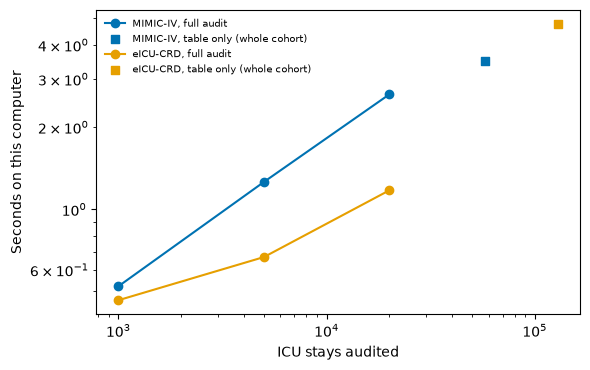

In [23]:
timing, AUDITS = [], {}
for db in ("mimic-iv", "eicu"):
    c_all = LOCAL[db]["c"].reset_index()
    Fc = pd.read_parquet(P1_DATA / f"features_clean_24h_{db}.parquet").set_index("entity_id")
    for n in AUDIT_SIZES + ["all"]:
        cs = c_all if n == "all" else sample_by_patient(c_all, n, stable_seed("timing", db, n))
        if n != "all" and len(cs) < 0.5 * n:
            continue
        ids = cs["stay_id"].tolist()
        data = cs.merge(Fc, left_on="stay_id", right_index=True, how="left")
        fcols = ["age", "female"] + list(Fc.columns)
        full = n != "all"
        prov = pd.read_parquet(P1_DATA / f"provenance_clean_24h_{db}.parquet", filters=[("entity_id", "in", ids)]) if full else None
        kw = dict(label="mortality", split="split_patient", dataset=db, patient_id="patient_id", encounter_id="encounter_id",
                  stay_id="stay_id", site_id="site_id" if db == "eicu" else None, index_time="index_time",
                  feature_columns=fcols, split_strategy="patient")
        if full:
            kw.update(outcome_time="mortality_time", eligibility_time="eligibility_time", calendar_time="calendar_period",
                      events=prov, event_entity="stay_id")
        t0 = time.perf_counter()
        res = ilc.LeakageAudit(data, **kw).run()
        secs = time.perf_counter() - t0
        cnt = res.counts
        timing.append({"database": db, "stays": len(cs), "mode": "full" if full else "table only",
                       "provenance_rows": 0 if prov is None else len(prov), "seconds": secs,
                       "fail": cnt.get("fail", 0), "warn": cnt.get("warn", 0), "pass": cnt.get("pass", 0)})
        if n == max(AUDIT_SIZES) or (n == "all" and db not in AUDITS):
            AUDITS[db] = (res, len(cs), "full" if full else "table only")
timing = pd.DataFrame(timing)
save_table(timing, "audit_runtime")
display(timing.round(2))
fig, ax = plt.subplots(figsize=(6, 3.8))
for k, db in enumerate(("mimic-iv", "eicu")):
    d = timing[(timing["database"] == db) & (timing["mode"] == "full")]
    ax.plot(d["stays"], d["seconds"], marker="o", color=OKABE[k], label=f"{LABEL[db]}, full audit")
    d2 = timing[(timing["database"] == db) & (timing["mode"] == "table only")]
    ax.scatter(d2["stays"], d2["seconds"], marker="s", color=OKABE[k], label=f"{LABEL[db]}, table only (whole cohort)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("ICU stays audited")
ax.set_ylabel("Seconds on this computer")
ax.legend(fontsize=7, frameon=False)
fig.tight_layout()
save_fig(fig, "fig_audit_runtime")

## 14. ICU-LEAK checklist and audit card

**Checklist.** Each Part 2 mechanism becomes one checklist item: a yes/no question for authors, assessors, procurement
teams and model owners. Items are ranked by **priority**: estimated prevalence in the literature multiplied by the
median AUROC inflation measured in Part 2. Priority is the AUROC optimism each item contributes to an average study.

Each item lists:
* the `icu-leakage-check` check that verifies it;
* the PROBAST+AI domain it falls under;
* whether it concerns the independence of training and test data (FDA Good Machine Learning Practice principle 4, and
  the test data independence element of the FDA draft guidance on AI-enabled device software functions, January 2025);
* data governance for training, validation and testing data (EU AI Act, Article 10).

**Audit card.** A one-page summary of the audit of the certified baseline, with data hashes, that a developer could
attach to a model submission or a procurement file.

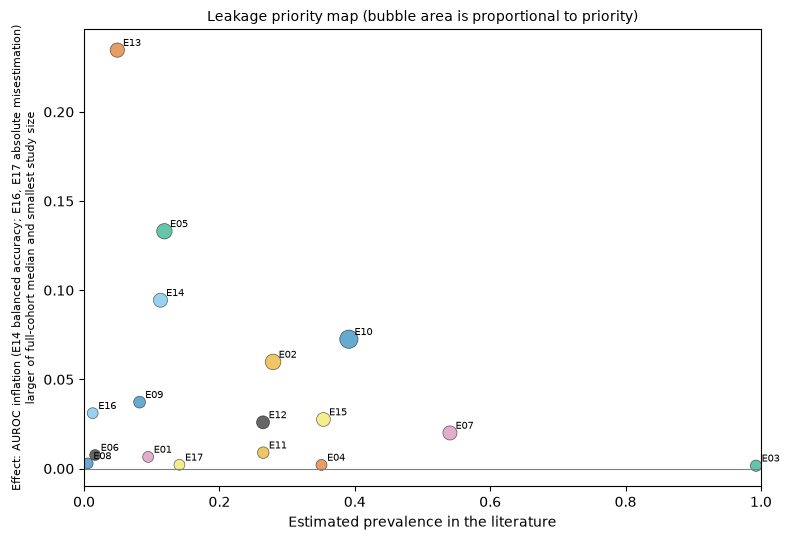

,priority_rank,mechanism,family,estimated_prevalence,median_auroc_inflation_full_cohort,mean_inflation_at_500_stays,priority,verified_by_check
9,1,E10,Post-outcome instances,0.3912,0.0725,NaN,0.0284,outcome_timing
1,2,E02,Timing,0.2792,0.0598,NaN,0.0167,"event_timing, truncation_invariance"
4,3,E05,Hindsight,0.1187,0.1331,NaN,0.0158,hindsight_features
12,4,E13,Resampling,0.0491,0.0589,0.2346,0.0115,synthetic_samples
6,5,E07,Undated or late source,0.5406,0.0200,NaN,0.0108,hindsight_features (undated sources)
13,6,E14,Evaluation reuse,0.1129,0.0014,0.0944,0.0107,threshold_selection
14,7,E15,Evaluation reuse,0.3537,0.0002,0.0275,0.0097,declarations
11,8,E12,Preprocessing,0.2644,0.0000,0.0259,0.0069,declarations
8,9,E09,First-day summary,0.0820,0.0372,NaN,0.0031,"hindsight_features, eligibility_timing"
10,10,E11,Preprocessing,0.2647,0.0000,0.0089,0.0024,preprocessing_fit


Evidence pack: ['audit_card_eicu.md', 'audit_card_mimic-iv.md', 'icu_leak_checklist.md']


In [24]:
QUESTIONS = {
    "E01": "Were training and test sets split by patient, so that no patient contributes stays to both?",
    "E02": "Is every feature computed only from data recorded up to the prediction time?",
    "E03": "Is every feature restricted to results available (stored or verified) by the prediction time, not only charted before it?",
    "E04": "Are infusions, ventilation and other interval records still running at the prediction time truncated or prorated?",
    "E05": "Are length of stay, discharge information and other end-of-stay fields excluded from the predictors?",
    "E06": "Are outcome fields and scores computed with the outcome (for example recorded hospital mortality) excluded from the predictors?",
    "E07": "Are diagnosis and billing codes taken only from earlier admissions, not the admission being predicted?",
    "E08": "Are code status, care limitation and end-of-life documentation restricted to entries made before the prediction time?",
    "E09": "Are severity scores used only when their measurement window ends by the prediction time?",
    "E10": "Were patients who already had the outcome at the prediction time excluded?",
    "E11": "Were imputation, scaling and other preprocessing fitted on the training set only?",
    "E12": "Was feature selection performed on the training set only?",
    "E13": "Was resampling (for example SMOTE) applied inside the training set only, with the test set left untouched?",
    "E14": "Was the decision threshold chosen without the test set?",
    "E15": "Were hyperparameters and the final model chosen without the test set?",
    "E16": "If validation is called temporal, is it ordered by true calendar time (in MIMIC-IV, anchor_year_group), not shifted dates?",
    "E17": "If validation is called external, does the external set share no hospitals or patients with the development data (MIMIC-III and MIMIC-IV overlap in 2008 to 2012)?",
}
CHECKS = {"E01": "entity_overlap, duplicate_records", "E02": "event_timing, truncation_invariance", "E03": "event_timing",
          "E04": "event_timing", "E05": "hindsight_features", "E06": "hindsight_features, outcome_proxies",
          "E07": "hindsight_features (undated sources)", "E08": "outcome_proxies", "E09": "hindsight_features, eligibility_timing",
          "E10": "outcome_timing", "E11": "preprocessing_fit", "E12": "declarations", "E13": "synthetic_samples",
          "E14": "threshold_selection", "E15": "declarations", "E16": "temporal_order", "E17": "site_overlap"}
PROBAST = {"E01": "Analysis", "E02": "Predictors", "E03": "Predictors", "E04": "Predictors", "E05": "Predictors",
           "E06": "Predictors / Outcome", "E07": "Predictors", "E08": "Predictors", "E09": "Predictors",
           "E10": "Participants and data sources / Outcome", "E11": "Analysis", "E12": "Analysis", "E13": "Analysis",
           "E14": "Analysis", "E15": "Analysis", "E16": "Participants and data sources / Analysis",
           "E17": "Participants and data sources / Analysis"}
INDEPENDENCE = {"E01", "E11", "E12", "E13", "E14", "E15", "E16", "E17"}
IND_BY_MECH = {}
for d in INDICATORS:
    IND_BY_MECH.setdefault(d["mechanism"].rstrip("b"), d["id"])

MISESTIMATION = {"E16", "E17"}
thr = pd.read_csv(P2 / "results" / "tables" / "threshold_effects.csv")
thr_ba = thr[thr["metric"] == "balanced_accuracy"]["difference"]
check_rows = []
for k, mech in enumerate(QUESTIONS, start=1):
    i = IND_BY_MECH.get(mech)
    lit_mech = IND[i]["mechanism"] if i else mech
    pr = prevalence.set_index("indicator").loc[i] if i else None
    prev = float(pr["estimated_prevalence"]) if pr is not None else np.nan
    eff = p2.loc[p2["mechanism"] == lit_mech, "difference"]
    if mech in MISESTIMATION:
        eff, metric = eff.abs(), "absolute AUROC misestimation"
    elif mech == "E14":
        eff, metric = thr_ba, "balanced accuracy"
    else:
        metric = "AUROC"
    small = size_summary[(size_summary["mechanism"] == lit_mech) & (size_summary["size"] == min(SIZES))]
    check_rows.append({
        "item": k, "mechanism": mech, "question": QUESTIONS[mech], "family": MECH[mech][1],
        "literature_indicator": i or "", "literature_mechanism": lit_mech, "effect_metric": metric, "estimated_prevalence": prev,
        "median_auroc_inflation_full_cohort": float(eff.median()) if len(eff) else np.nan,
        "max_auroc_inflation_full_cohort": float(eff.max()) if len(eff) else np.nan,
        f"mean_inflation_at_{min(SIZES)}_stays": float(small["mean_difference"].mean()) if len(small) else np.nan,
        "verified_by_check": CHECKS[mech], "probast_ai_domain": PROBAST[mech],
        "training_test_independence": "yes" if mech in INDEPENDENCE else "",
        "data_governance": "yes",
    })
checklist = pd.DataFrame(check_rows)
infl_for_priority = checklist["median_auroc_inflation_full_cohort"].clip(lower=0).fillna(0)
small_col = f"mean_inflation_at_{min(SIZES)}_stays"
infl_for_priority = np.maximum(infl_for_priority, checklist[small_col].clip(lower=0).fillna(0))
checklist["priority"] = checklist["estimated_prevalence"].fillna(0) * infl_for_priority
checklist["priority_rank"] = checklist["priority"].rank(ascending=False, method="min").astype(int)
checklist = checklist.sort_values("priority_rank")
save_table(checklist, "icu_leak_checklist")

lines = ["# ICU-LEAK checklist (17 items)", "",
         "Answer each question for the model under review. Items are ordered by evidence-based priority: estimated prevalence",
         "in published MIMIC-IV and eICU-CRD prediction studies multiplied by the AUROC inflation measured when the practice",
         "is switched on in a controlled pipeline.", "",
         "| Rank | Item | Question | Prevalence | Effect (median, full cohort) | Effect at smallest study size | Verified by |",
         "|---|---|---|---|---|---|---|"]
for r in checklist.itertuples():
    lines.append(f"| {r.priority_rank} | {r.mechanism} | {r.question} | "
                 f"{'' if np.isnan(r.estimated_prevalence) else f'{r.estimated_prevalence:.0%}'} | "
                 f"{'' if np.isnan(r.median_auroc_inflation_full_cohort) else f'{r.median_auroc_inflation_full_cohort:+.3f} ({r.effect_metric})'} | "
                 f"{'' if np.isnan(getattr(r, small_col)) else f'{getattr(r, small_col):+.3f}'} | `{r.verified_by_check}` |")
lines += ["", "Prevalence basis: " + ("corrected with blinded reference coding by a large language model (174 studies)." if VALIDATED else "automated screening, not yet validated.")]
(PACK_DIR / "icu_leak_checklist.md").write_text("\n".join(lines), encoding="utf-8")

fig, ax = plt.subplots(figsize=(8, 5.5))
cl = checklist.dropna(subset=["estimated_prevalence"])
yv = np.maximum(cl["median_auroc_inflation_full_cohort"].fillna(0), cl[small_col].fillna(0))
ax.scatter(cl["estimated_prevalence"], yv, s=60 + 4000 * cl["priority"], alpha=0.6,
           color=[OKABE[k % len(OKABE)] for k in range(len(cl))], edgecolor="black", lw=0.5)
for r, yy in zip(cl.itertuples(), yv):
    ax.annotate(r.mechanism, (r.estimated_prevalence, yy), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("Estimated prevalence in the literature")
ax.set_ylabel("Effect: AUROC inflation (E14 balanced accuracy; E16, E17 absolute misestimation)\nlarger of full-cohort median and smallest study size", fontsize=8)
ax.set_xlim(0, 1)
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Leakage priority map (bubble area is proportional to priority)", fontsize=10)
fig.tight_layout()
save_fig(fig, "fig_priority_map")
display(checklist[["priority_rank", "mechanism", "family", "estimated_prevalence", "median_auroc_inflation_full_cohort",
                   small_col, "priority", "verified_by_check"]].round(4))

for db, (res, n_audit, mode) in AUDITS.items():
    fr = res.to_frame()
    card = [f"# Leakage audit card: {LABEL[db]} in-hospital mortality reference pipeline", "",
            f"* Audited stays: {n_audit:,} ({mode} audit), prediction at 24 hours after ICU admission",
            "* Split: patient-level 70 / 10 / 20; features: availability-filtered, prorated 24-hour windows",
            f"* Result: {res.counts.get('fail', 0)} fail, {res.counts.get('warn', 0)} warn, {res.counts.get('pass', 0)} pass, "
            f"{res.counts.get('skipped', 0)} skipped",
            f"* Software: icu-leakage-check {ilc.__version__}; Python {ENV['python']}",
            f"* Evidence chain: Part 1 {part1_manifest['chain_sha256'][:16]}..., Part 2 {part2_manifest['chain_sha256'][:16]}...", "",
            "## Checks", "", "| Check | Leakage type | Status | Severity |", "|---|---|---|---|"]
    for r in fr.itertuples():
        card.append(f"| {r.check_id} | {r.leakage_type} | {r.status} | {r.severity} |")
    card += ["", "## What the checks protect against (inflation measured when each leak is switched on)", "",
             "| Item | Mechanism | Median AUROC inflation |", "|---|---|---|"]
    for r in checklist.sort_values("item").itertuples():
        if np.isfinite(r.median_auroc_inflation_full_cohort):
            card.append(f"| {r.mechanism} | {MECH[r.mechanism][0]} | {r.median_auroc_inflation_full_cohort:+.3f} |")
    (PACK_DIR / f"audit_card_{db}.md").write_text("\n".join(card), encoding="utf-8")
    res.to_html(PRIVATE_DIR / f"audit_reference_{db}.html")
print("Evidence pack:", sorted(p.name for p in PACK_DIR.iterdir()))

## 15. Key numbers, study summary and reproducibility manifest

{
  "literature": {
    "query": "(TITLE:\"MIMIC-IV\" OR ABSTRACT:\"MIMIC-IV\" OR TITLE:\"MIMIC IV\" OR ABSTRACT:\"MIMIC IV\" OR TITLE:\"MIMIC-4\" OR ABSTRACT:\"MIMIC-4\" OR TITLE:\"eICU\" OR ABSTRACT:\"eICU\" OR TITLE:\"eICU-CRD\" OR ABSTRACT:\"eICU-CRD\" OR TITLE:\"eICU Collaborative Research Database\" OR ABSTRACT:\"eICU Collaborative Research Database\") AND (TITLE:predict* OR ABSTRACT:predict* OR TITLE:prognos* OR ABSTRACT:prognos* OR TITLE:nomogram* OR ABSTRACT:nomogram* OR TITLE:\"machine learning\" OR ABSTRACT:\"machine learning\" OR TITLE:\"deep learning\" OR ABSTRACT:\"deep learning\" OR TITLE:\"risk score\" OR ABSTRACT:\"risk score\" OR TITLE:\"early warning\" OR ABSTRACT:\"early warning\" OR TITLE:\"risk model\" OR ABSTRACT:\"risk model\") AND FIRST_PDATE:[2020-08-01 TO 2026-09-30] AND (SRC:MED OR SRC:PMC OR SRC:PPR)",
    "search window": "2020-08-01 to 2026-09-30",
    "retrieved": "2026-10-16T04:52:35Z",
    "records reported by Europe PMC": 3957,
    "unique records": 3

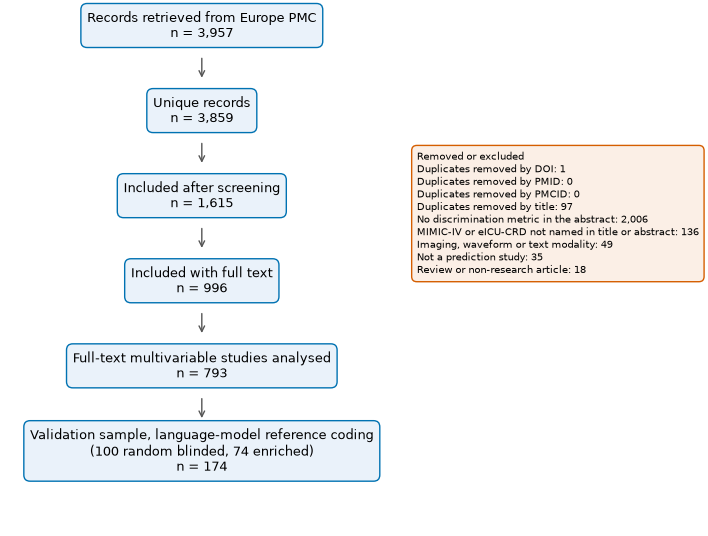


75 files hashed; literature snapshot 1027 files; chain digest 08415e70047ea1cc96d3c4ab2389589c1ffae504e19f781adbfd709d1d457104; runtime 2.9 min


In [25]:
fl = dict(flow)
key = {
    "literature": {
        "query": QUERY, "search window": f"{SEARCH_START} to {SEARCH_END}", "retrieved": search_meta.get("retrieved_utc"),
        "records reported by Europe PMC": search_meta.get("hit_count"), "unique records": fl.get("Unique records"),
        "included after screening": fl.get("Included after screening"),
        "included with full text": fl.get("Included with full text"),
        "full-text multivariable studies analysed": len(analysis),
        "validation": f"{len(reference)} coded papers" if VALIDATED else "not yet coded",
    },
    "prevalence (estimated share at risk)": {f"{r.indicator} {r.name}": round(float(r.estimated_prevalence), 4)
                                             for r in prevalence.itertuples()},
    "transparency (share of studies)": {r.indicator: round(float(r.share_of_studies), 4) for r in transparency.itertuples()},
    "reported AUROC and leakage": assoc_summary,
    "sample-size dependence (mean AUROC inflation, MIMIC-IV, logistic)": {
        mech: {int(s): round(float(v), 4) for s, v in size_summary[(size_summary["database"] == "mimic-iv") & (size_summary["model"] == "logistic")
                                                                   & (size_summary["mechanism"] == mech)].set_index("size")["mean_difference"].items()}
        for mech in SIZE_MECHS},
    "additivity factor": [round(ADDITIVITY, 4), round(ADDITIVITY_SE, 4)],
    "field-level optimism": {r.quantity: [round(float(r.estimate), 4), None if pd.isna(r.lower_95) else round(float(r.lower_95), 4),
                                          None if pd.isna(r.upper_95) else round(float(r.upper_95), 4)] for r in field.itertuples()},
    "field-level optimism, explicit practices only": {r.quantity: [round(float(r.estimate), 4), round(float(r.lower_95), 4),
                                                                   round(float(r.upper_95), 4)] for r in field_explicit.itertuples()},
    "audit runtime (seconds)": {f"{LABEL[r.database]} {r.stays:,} stays {r.mode}": round(float(r.seconds), 1) for r in timing.itertuples()},
    "checklist top five": [f"{r.mechanism} {MECH[r.mechanism][0]}" for r in checklist.head(5).itertuples()],
}
key["field-level optimism, main scenario (Table 3)"] = sens.iloc[0].to_dict()
key["reference coding"] = "Claude Opus 5.5, 100 random studies blinded to automated values, 74 enriched unblinded"
if VALIDATED:
    key["validation agreement, pooled"] = det[det["indicator"] == "pooled"].iloc[0].to_dict()
(RESULTS_DIR / "key_numbers_part3.json").write_text(json.dumps(key, indent=2, default=str))
print(json.dumps(key, indent=2, default=str)[:6000])

flow_df = pd.DataFrame(flow, columns=["step", "n"])
save_table(flow_df, "literature_flow")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.axis("off")
boxes = [("Records retrieved from Europe PMC", fl.get("Records retrieved from Europe PMC")), ("Unique records", fl.get("Unique records")),
         ("Included after screening", fl.get("Included after screening")), ("Included with full text", fl.get("Included with full text")),
         ("Full-text multivariable studies analysed", len(analysis)),
         ("Validation sample, language-model reference coding\n(100 random blinded, 74 enriched)", len(reference) if VALIDATED else 0)]
for k, (lab, n) in enumerate(boxes):
    yy = 1 - k * 0.17
    ax.text(0.33, yy, f"{lab}\nn = {n:,}" if n is not None else lab, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.5", fc="#EAF2FA", ec="#0072B2"), transform=ax.transAxes)
    if k < len(boxes) - 1:
        ax.annotate("", xy=(0.33, yy - 0.11), xytext=(0.33, yy - 0.06), xycoords="axes fraction",
                    arrowprops=dict(arrowstyle="->", color="#555555"))
ex = [f"{s.replace('Excluded: ', '')}: {n:,}" for s, n in flow if s.startswith("Excluded") or s.startswith("Duplicates")]
ax.text(0.70, 0.75, "Removed or excluded\n" + "\n".join(ex), ha="left", va="top", fontsize=7.5,
        bbox=dict(boxstyle="round,pad=0.5", fc="#FBEFE6", ec="#D55E00"), transform=ax.transAxes)
save_fig(fig, "fig_literature_flow")

k1 = json.loads((P1 / "results" / "key_numbers_part1.json").read_text())
k2 = json.loads((P2 / "results" / "key_numbers_part2.json").read_text())
summ = ["# Study summary across Parts 1 to 3", "", "## Part 1: cohorts and risk surface", "", "```", json.dumps(k1, indent=2), "```", "",
        "## Part 2: controlled inflation and detection", "", "```", json.dumps(k2, indent=2), "```", "",
        "## Part 3: literature, sample size and field-level impact", "", "```", json.dumps(key, indent=2, default=str), "```"]
(RESULTS_DIR / "study_summary.md").write_text("\n".join(summ), encoding="utf-8")


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


files = []
for folder in (RESULTS_DIR, PRIVATE_DIR, CODING_DIR):
    for p in sorted(folder.rglob("*")):
        if p.is_file() and p.name != "manifest_part3.json":
            files.append({"file": str(p.relative_to(PART_DIR)).replace("\\", "/"), "bytes": p.stat().st_size, "sha256": sha256_file(p)})
snap_files = sorted(p for p in SNAP.rglob("*") if p.is_file())
snap_digest = hashlib.sha256("".join(f"{p.name}:{sha256_file(p)}\n" for p in snap_files).encode()).hexdigest()
chain = hashlib.sha256(part2_manifest["chain_sha256"].encode())
for f in sorted(files, key=lambda r: r["file"]):
    if f["file"].startswith(("private_reports/", "coding/")) or f["file"].endswith(("key_numbers_part3.json", "study_summary.md")):
        continue
    if f["file"].endswith(("audit_runtime.csv", "fig_audit_runtime.png", "fig_audit_runtime.pdf")):
        continue
    chain.update(f"{f['file']}:{f['sha256']}\n".encode())
chain.update(snap_digest.encode())
chain.update(json.dumps(CONFIG, sort_keys=True).encode())
chain.update(json.dumps({k: v for k, v in ENV.items() if k not in ("run_started_utc", "platform")}, sort_keys=True).encode())
manifest = {"part": 3, "previous_chain_sha256": part2_manifest["chain_sha256"], "environment": ENV, "configuration": CONFIG,
            "literature_snapshot": {"files": len(snap_files), "sha256": snap_digest, **search_meta},
            "files": files, "chain_sha256": chain.hexdigest(), "runtime_minutes": round((time.time() - RUN_START) / 60, 1)}
(PART_DIR / "manifest_part3.json").write_text(json.dumps(manifest, indent=2))
(RESULTS_DIR / "manifest_part3.json").write_text(json.dumps(manifest, indent=2))
print(f"\n{len(files)} files hashed; literature snapshot {len(snap_files)} files; chain digest {manifest['chain_sha256']}; "
      f"runtime {manifest['runtime_minutes']} min")

## What to share and what to keep

**Shareable (aggregate):**
* everything in `results/tables` and `results/figures`;
* the checklist and audit cards in `results/evidence_pack`;
* `key_numbers_part3.json` and `study_summary.md`;
* `literature_records.csv`: identifiers and screening decisions only, so anyone can rebuild the corpus.

**Keep local:**
* `private_reports/`: paper-level indicator values and expected optimism, plus the reference audit reports. Naming
  individual papers needs the validated coding, and ideally a second coder, first.
* `literature_snapshot/`: full texts carry their own licences, so share the identifiers rather than the files.
* all Part 1 and Part 2 patient-level files, under the PhysioNet data use agreement.

**After coding:** rerun the notebook. Downloads, simulations and the combination experiment are reused, and every
prevalence, optimism and checklist number switches from screening estimates to validated estimates.